# Identifying Patterns in Global E-Commerce Sales

Executable workflow using only the supplied workbook and assignment brief. Money is merchandise value in pounds; cancellation allocation is retrospective. See the report for scope and limitations.

In [1]:
# Locate the repository, import the shared definitions, and keep execution reproducible.
from pathlib import Path
import os, sys, json
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'AGENTS.md').exists())
os.chdir(root)
sys.path.insert(0, str(root/'src'))

## Load, clean and chronologically net cancellations

The following cell contains the complete stage implementation. It runs the same functions used by the command-line pipeline.

In [2]:
"""Read source, run fixed regression checks, then chronologically reverse units."""
import time
import re
import json
from collections import defaultdict
import numpy as np
import pandas as pd
from common import ROOT, start, save_results, finish

ORIGINAL = ['POST','D','M','BANK CHARGES','C2','DOT','PADS','CRUK','TEST001','TEST002','ADJUST','ADJUST2','B']
EXPECTED = dict(duplicates=34335, nonproduct=5581, cancellations=18046,
                invalid=5986, missing_id=226844, purchases=776579, customers=5852)

def net_cancellations(purchases, cancellations):
    """LIFO by customer/product; cancellation events precede equal-time purchases."""
    p = purchases.sort_values(['InvoiceDate','source_row']).reset_index(drop=True).copy()
    c = cancellations.sort_values(['InvoiceDate','source_row']).reset_index(drop=True).copy()
    remaining = p.Quantity.to_numpy(dtype=float,copy=True)
    reversed_units = np.zeros(len(c))
    keys = set(zip(c.loc[c.CustomerID.notna(),'CustomerID'],c.loc[c.CustomerID.notna(),'StockCode']))
    events = defaultdict(list)
    for i, row in enumerate(p[['CustomerID','StockCode','InvoiceDate']].itertuples(index=False,name=None)):
        customer,stock,date=row
        if (customer,stock) in keys:
            events[(customer,stock)].append((date,1,i))
    for i,row in enumerate(c[['CustomerID','StockCode','InvoiceDate']].itertuples(index=False,name=None)):
        customer,stock,date=row
        if pd.notna(customer) and c.iloc[i].Quantity < 0:
            events[(customer,stock)].append((date,0,i))
    for ev in events.values():
        stack=[]
        for _,kind,i in sorted(ev):
            if kind:
                stack.append(i)
            else:
                need = -float(c.iloc[i].Quantity)
                while need > 0 and stack:
                    j=stack[-1]
                    take=min(remaining[j],need)
                    remaining[j]-=take
                    need-=take
                    reversed_units[i]+=take
                    if remaining[j] == 0:
                        stack.pop()
    c['cancelled_units']=np.maximum(-c.Quantity.to_numpy(),0)
    c['reversed_units']=reversed_units
    c['unmatched_units']=c.cancelled_units-c.reversed_units
    c['matched_flag']=np.select([(c.cancelled_units>0)&(c.unmatched_units==0),c.reversed_units>0],['matched','partly matched'],default='unmatched')
    p['OriginalQuantity']=p.Quantity
    p['Quantity']=remaining
    p['Revenue']=p.Quantity*p.Price
    return p.loc[p.Quantity>0].copy(),c,p

def main():
    start()
    sheets=pd.read_excel(ROOT/'inputs/online_retail_II.xlsx',sheet_name=None,engine='calamine')
    assert list(sheets)==['Year 2009-2010','Year 2010-2011']
    R={'source':{'file':'online_retail_II.xlsx','access_date':'2026-10-16',
       'url':'https://archive.ics.uci.edu/dataset/502/online+retail+ii','reader':'pandas calamine engine'},'sheets':{},'audit':[]}
    R['assignment']=json.loads((ROOT/'docs/brief_metadata.json').read_text())
    for name,df in sheets.items():
        R['sheets'][name]={'shape':df.shape,'dtypes':df.dtypes.astype(str).to_dict(),
                          'nulls':df.isna().sum().to_dict(),'start':df.InvoiceDate.min(),'end':df.InvoiceDate.max()}
    raw=pd.concat(sheets.values(),ignore_index=True)
    R['source'].update(rows=len(raw),columns=raw.shape[1],start=raw.InvoiceDate.min(),end=raw.InvoiceDate.max())
    R['source']['overlap_start']=max(x.InvoiceDate.min() for x in sheets.values())
    R['source']['overlap_end']=min(x.InvoiceDate.max() for x in sheets.values())
    def audit(before,after,reason):
        R['audit'].append(dict(before=int(before),removed=int(before-after),after=int(after),reason=reason))
    df=raw.drop_duplicates().copy()
    actual={'duplicates':len(raw)-len(df)}
    audit(len(raw),len(df),'Remove exact duplicate rows across both sheets, including their overlapping dates; no fuzzy deduplication.')
    df=df.rename(columns={'Customer ID':'CustomerID'})
    df['source_row']=df.index
    df['StockCode']=df.StockCode.astype(str).str.strip().str.upper()
    df['Invoice']=df.Invoice.astype(str).str.strip().str.upper()
    original=df.loc[~df.StockCode.isin(ORIGINAL)].copy()
    actual['nonproduct']=len(df)-len(original)
    c=original.loc[original.Invoice.str.startswith('C')]
    actual['cancellations']=len(c)
    p=original.loc[~original.Invoice.str.startswith('C')]
    valid=p.loc[(p.Quantity>0)&(p.Price>0)]
    actual['invalid']=len(p)-len(valid)
    actual['missing_id']=int(valid.CustomerID.isna().sum())
    valid=valid.loc[valid.CustomerID.notna()]
    actual.update(purchases=len(valid),customers=valid.CustomerID.nunique())
    print('Original-list regression:',actual,flush=True)
    assert actual==EXPECTED, (actual,EXPECTED)
    R['regression']=actual
    odd=original.loc[~original.StockCode.str.fullmatch(r'\d{5}[A-Z]*')]
    evidence=odd.groupby('StockCode').agg(rows=('Invoice','size'),descriptions=('Description',lambda s:'; '.join(s.dropna().astype(str).unique()[:8]))).reset_index()
    # Only service/fee/voucher descriptions justify an extension. Irregular product codes stay.
    extra=[code for code in evidence.StockCode if code in ['AMAZONFEE','S'] or re.fullmatch(r'GIFT_\d+_\d+',code)]
    evidence['excluded']=evidence.StockCode.isin(extra)
    evidence['justification']=evidence.StockCode.map(lambda code: 'Amazon fee, not merchandise.' if code=='AMAZONFEE' else 'SAMPLES code: non-catalog sample/accounting lines, excluded consistently from sales and cancellations.' if code=='S' else 'Gift voucher liability, excluded from physical-merchandise sales.' if code in extra else 'Irregular syntax alone is not evidence of a non-product; retained.')
    evidence.to_csv(ROOT/'outputs/docs/non_product_evidence.csv',index=False)
    R['nonproduct']={'original':ORIGINAL,'extra':extra,'extra_rows':int(original.StockCode.isin(extra).sum()),'evidence':evidence.to_dict('records')}
    full=df.loc[~df.StockCode.isin(ORIGINAL+extra)].copy()
    audit(len(df),len(original),'Remove only original non-product code list, after uppercase and whitespace normalisation; fixed-list regression passed.')
    audit(len(original),len(full),'Extend exclusions only with documented fee, sample and gift-voucher codes; evidence is in non_product_evidence.csv.')
    c=full.loc[full.Invoice.str.startswith('C')].copy()
    p=full.loc[~full.Invoice.str.startswith('C')].copy()
    audit(len(full),len(p),'Separate all cancellation-invoice rows into a retained cancellation table; these are not booked as sales.')
    valid=p.loc[(p.Quantity>0)&(p.Price>0)].copy()
    audit(len(p),len(valid),'Remove non-cancellation rows with nonpositive quantity or price; no price imputation.')
    missing=valid.loc[valid.CustomerID.isna()]
    R['missing_id']={'rows':len(missing),'revenue':(missing.Quantity*missing.Price).sum(),
                     'purchase_revenue_share':(missing.Quantity*missing.Price).sum()/(valid.Quantity*valid.Price).sum(),
                     'purchase_rows_share':len(missing)/len(valid)}
    p=valid.loc[valid.CustomerID.notna()].copy()
    audit(len(valid),len(p),'Exclude missing-ID positive purchase rows from linked customer analysis; their gross merchandise value and coverage loss are reported separately.')
    tic=time.perf_counter()
    net,c,all_lines=net_cancellations(p,c)
    runtime=time.perf_counter()-tic
    audit(len(p),len(net),'Drop fully reversed purchase lines after chronological customer/product LIFO matching; partly reversed lines retain remaining units at original purchase prices. Unmatched cancellation units remain outside net sales.')
    gross=(p.Quantity*p.Price).sum()
    R['netting']={'runtime_seconds':runtime,'cancellation_rows':len(c),
       'matched':int((c.matched_flag=='matched').sum()),'partly_matched':int((c.matched_flag=='partly matched').sum()),
       'unmatched':int((c.matched_flag=='unmatched').sum()),'cancelled_units':c.cancelled_units.sum(),
       'reversed_units':c.reversed_units.sum(),'unmatched_units':c.unmatched_units.sum(),
       'unmatched_unit_share':c.unmatched_units.sum()/c.cancelled_units.sum(),
       'gross_revenue':gross,'net_revenue':net.Revenue.sum(),'reversed_revenue':gross-net.Revenue.sum(),
       'lines_dropped':len(p)-len(net),'lines_partly_reversed':int(((all_lines.Quantity>0)&(all_lines.Quantity<all_lines.OriginalQuantity)).sum()),
       'net_lines':len(net),'customers':net.CustomerID.nunique(),'cancellation_missing_id_rows':int(c.CustomerID.isna().sum()),
       'nonnegative_cancellation_rows':int((c.Quantity>=0).sum())}
    for customer,invoice in [(16446,'581483'),(12346,'541431')]:
        assert not ((net.CustomerID==customer)&(net.Invoice==invoice)).any()
    R['cleaning']={'purchase_invoices':p.Invoice.nunique(),'net_invoices':net.Invoice.nunique(),
                   'description_nulls_retained':int(net.Description.isna().sum()),'price_matching':'Customer and product only; reverse at purchase price, not cancellation price.'}
    net.to_parquet(ROOT/'data/net_purchases.parquet',index=False)
    p.to_parquet(ROOT/'data/gross_purchases.parquet',index=False)
    c.to_parquet(ROOT/'data/cancellations.parquet',index=False)
    pd.DataFrame(R['audit']).to_csv(ROOT/'outputs/docs/cleaning_audit.csv',index=False)
    save_results(R)
    print(R['netting'],flush=True)
    finish('Cleaning and netting','Fixed regression passed. Both specified extreme purchases fully reversed; native JSON and audit saved. Strict earlier-time LIFO matching verified; missing-ID cancellations cannot be linked. Figures and downstream modelling remain unverified.')

if __name__=='__main__':
    main()


Original-list regression: {'duplicates': 34335, 'nonproduct': 5581, 'cancellations': 18046, 'invalid': 5986, 'missing_id': 226844, 'purchases': 776579, 'customers': 5852}


{'runtime_seconds': 12.776178999999956, 'cancellation_rows': 17914, 'matched': 15872, 'partly_matched': 127, 'unmatched': 1915, 'cancelled_units': np.int64(467739), 'reversed_units': np.float64(450047.0), 'unmatched_units': np.float64(17692.0), 'unmatched_unit_share': np.float64(0.03782451324349691), 'gross_revenue': np.float64(17068582.72), 'net_revenue': np.float64(16338578.6), 'reversed_revenue': np.float64(730004.1199999992), 'lines_dropped': 6026, 'lines_partly_reversed': 9677, 'net_lines': 770553, 'customers': 5839, 'cancellation_missing_id_rows': 328, 'nonnegative_cancellation_rows': 0}


Fixed regression passed. Both specified extreme purchases fully reversed; native JSON and audit saved. Strict earlier-time LIFO matching verified; missing-ID cancellations cannot be linked. Figures and downstream modelling remain unverified.


## Exploratory analysis

The following cell contains the complete stage implementation. It runs the same functions used by the command-line pipeline.

In [3]:
"""Descriptive findings with independently ranked products and common date axes."""
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator, EngFormatter
from common import ROOT, start, read_net, load_results, save_results, figure, finish

def partial(ax, date):
    ax.axvspan(date,date+pd.offsets.MonthBegin(1),color='#d17a22',alpha=.18)
    ax.text(.98,.93,'Partial final month',transform=ax.transAxes,ha='right',fontsize=9,color='#8a4800')

def main():
    start()
    R=load_results()
    p=read_net()
    p['Month']=p.InvoiceDate.dt.to_period('M').dt.to_timestamp()
    monthly=p.groupby('Month').Revenue.sum().sort_index()
    last=p.InvoiceDate.max().to_period('M').to_timestamp()
    complete=monthly.loc[monthly.index!=last]
    q4=complete.index.quarter==4
    peaks=monthly.nlargest(3)
    season={'peak_months':{x.strftime('%B %Y'):v for x,v in peaks.items()},
            'q4_mean':complete.loc[q4].mean(),'rest_mean':complete.loc[~q4].mean(),
            'q4_rest_ratio':complete.loc[q4].mean()/complete.loc[~q4].mean(),
            'partial_month':last.strftime('%B %Y'),'last_date':p.InvoiceDate.max().strftime('%d %B %Y')}
    R['seasonal']=season
    R['monthly_revenue']={d.strftime('%Y-%m'):v for d,v in monthly.items()}
    fig,ax=plt.subplots(figsize=(11,5.5))
    ax.plot(monthly.index,monthly.values,color='#236b8e',marker='o')
    ax.set(title='Figure 1. Monthly net merchandise revenue',xlabel='Invoice month',ylabel='Net revenue (GBP)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.tick_params(axis='x',rotation=40)
    partial(ax,last)
    caption=f"Peak months: {', '.join(f'{k} (GBP {v:,.0f})' for k,v in season['peak_months'].items())}. Complete-month Q4/rest mean revenue ratio: {season['q4_rest_ratio']:.2f}. {season['partial_month']} ends {season['last_date']}. Reversals are attributed to the original sale month."
    figure(R,fig,'fig1_monthly_revenue',caption)
    product=p.groupby('StockCode').agg(revenue=('Revenue','sum'),units=('Quantity','sum'),customers=('CustomerID','nunique'),orders=('Invoice','nunique'),description=('Description','first'))
    product['value_per_order']=product.revenue/product.orders
    counts=p.groupby(['StockCode','CustomerID']).Invoice.nunique()
    product['repeat_customers']=counts.gt(1).groupby(level=0).sum()
    product['repeat_customer_share']=product.repeat_customers/product.customers
    product=product.reset_index()
    product.to_csv(ROOT/'data/product_summary.csv',index=False)
    product.to_csv(ROOT/'outputs/docs/product_summary.csv',index=False)
    leaders={metric:product.loc[product[metric].idxmax()].to_dict() for metric in ['revenue','units','customers']}
    R['products']={'leaders':leaders,'same_leader':len({v['StockCode'] for v in leaders.values()})==1}
    fig,axes=plt.subplots(1,3,figsize=(14,12))
    for ax,metric,label in zip(axes,['revenue','units','customers'],['Net revenue (GBP)','Net units','Distinct customers']):
        top=product.nlargest(10,metric).sort_values(metric)
        labels=[f"{r.StockCode}\n{str(r.description)[:12]}\n{r.customers:,} customers" for r in top.itertuples()]
        ax.barh(labels,top[metric],color='#236b8e')
        ax.set(xlabel=label,title=label)
        ax.tick_params(axis='y',labelsize=14)
        ax.tick_params(axis='x',labelsize=12)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.xaxis.set_major_formatter(EngFormatter(places=0,sep=''))
    fig.suptitle('Figure 2. Products ranked separately by each measure',fontweight='bold')
    caption='; '.join(f"{m} leader: {v['description']} ({v['StockCode']}), {v[m]:,.0f} {'GBP' if m=='revenue' else m}" for m,v in leaders.items())+('. The leaders differ.' if not R['products']['same_leader'] else '. One product leads all measures.')+' Each row shows its customer count; full names are in product_summary.csv.'
    figure(R,fig,'fig2_products',caption)
    country=p.groupby('Country').agg(revenue=('Revenue','sum'),customers=('CustomerID','nunique'),orders=('Invoice','nunique'),units=('Quantity','sum'))
    country['AOV']=country.revenue/country.orders
    country['revenue_per_customer']=country.revenue/country.customers
    country['units_per_order']=country.units/country.orders
    country['orders_per_customer']=country.orders/country.customers
    country.to_csv(ROOT/'data/country_summary.csv')
    country.to_csv(ROOT/'outputs/docs/country_summary.csv')
    exports=country.drop(index='United Kingdom').nlargest(10,'revenue')
    lead=exports.iloc[0]
    high=exports.AOV.idxmax()
    R['countries']={'all':country.reset_index().to_dict('records'),'top_exports':exports.reset_index().to_dict('records'),
       'leader':exports.index[0],'leader_revenue':lead.revenue,'leader_customers':lead.customers,
       'leader_AOV':lead.AOV,'leader_units_per_order':lead.units_per_order,'highest_AOV':high,
       'highest_AOV_value':country.loc[high,'AOV'],'highest_AOV_customers':country.loc[high,'customers'],
       'highest_AOV_units_per_order':country.loc[high,'units_per_order'],'UK_AOV':country.loc['United Kingdom','AOV'],
       'UK_units_per_order':country.loc['United Kingdom','units_per_order']}
    fig,axes=plt.subplots(2,2,figsize=(12,10))
    for ax,metric,label in zip(axes.flat,['revenue','customers','AOV','revenue_per_customer'],['Net revenue (GBP)','Distinct customers','Net average order value (GBP/order)','Net revenue per customer (GBP/customer)']):
        ax.barh(exports.index[::-1],exports[metric].values[::-1],color='#236b8e')
        ax.set(xlabel=label)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.xaxis.set_major_formatter(EngFormatter(places=0,sep=''))
    fig.suptitle('Figure 3. Highest-revenue export countries (United Kingdom excluded)',fontweight='bold')
    co=R['countries']
    caption=f"{co['leader']} leads exports: GBP {co['leader_revenue']:,.0f}, {co['leader_customers']:,.0f} customers. {high} has the largest AOV in this group: GBP {co['highest_AOV_value']:,.2f}, {co['highest_AOV_units_per_order']:,.1f} units/order, {co['highest_AOV_customers']:,.0f} customers; UK: GBP {co['UK_AOV']:,.2f}, {co['UK_units_per_order']:,.1f} units/order. Basket size and customer-base size are descriptive, not proof of buyer type."
    figure(R,fig,'fig3_countries',caption)
    c=pd.read_parquet(ROOT/'data/cancellations.parquet')
    gross=pd.read_parquet(ROOT/'data/gross_purchases.parquet')
    def invoice_month(df):
        return df.assign(Month=df.InvoiceDate.dt.to_period('M').dt.to_timestamp()).groupby('Month').Invoice.nunique()
    m=pd.concat([invoice_month(c.loc[c.CustomerID.notna()]).rename('cancelled'),invoice_month(gross).rename('purchase')],axis=1).fillna(0)
    m['rate']=m.cancelled/(m.cancelled+m.purchase)
    mc=m.loc[m.index!=last]
    cq=mc.index.quarter==4
    R['cancellations_monthly']={'rows':m.reset_index().to_dict('records'),'q4_mean':mc.loc[cq,'rate'].mean(),
       'rest_mean':mc.loc[~cq,'rate'].mean(),'definition':'Distinct identified-customer cancellation invoices divided by distinct identified-customer cancellation plus valid identified-customer gross purchase invoices; merchandise codes only. Same invoice ratio as the customer profiling feature.'}
    fig,ax=plt.subplots(figsize=(11,5.5))
    ax.bar(m.index,m.cancelled,width=20,color='#236b8e',label='Cancelled invoices')
    line=ax.twinx()
    line.plot(m.index,m.rate*100,color='#c66b26',marker='o',label='Cancellation invoice rate')
    ax.set(title='Figure 4. Cancellation invoices and invoice rate',xlabel='Invoice month',ylabel='Cancelled invoices (count)')
    line.set_ylabel('Cancelled / (cancelled + purchase invoices) (%)')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    ax.tick_params(axis='x',rotation=40)
    partial(ax,last)
    cr=R['cancellations_monthly']
    caption=f"Complete-month mean invoice cancellation rate: Q4 {cr['q4_mean']:.2%}; non-Q4 {cr['rest_mean']:.2%}. "
    caption+=('No descriptive Q4 elevation is observed. ' if cr['q4_mean']<=cr['rest_mean'] else 'Q4 is descriptively higher; this is not a significance or causal test. ')
    caption+='Both invoice counts use identified customers and merchandise codes; gross purchase invoices precede netting. Final month is partial.'
    figure(R,fig,'fig4_cancellations',caption)
    save_results(R)
    print(season,{k:v for k,v in co.items() if k not in ['all','top_exports']},flush=True)
    finish('Exploratory analysis','Figures saved with computed captions; finite axis limits and annotation locations checked. Product rankings computed separately; UK excluded by name. Final month omitted from seasonal mean comparisons. Visual inspection pending.')

if __name__=='__main__':
    main()


{'peak_months': {'November 2011': 1119164.27, 'November 2010': 1117670.23, 'October 2010': 976736.35}, 'q4_mean': np.float64(898830.5966666667), 'rest_mean': np.float64(589039.4666666667), 'q4_rest_ratio': np.float64(1.5259259311656763), 'partial_month': 'December 2011', 'last_date': '09 December 2011'} {'leader': 'EIRE', 'leader_revenue': np.float64(567785.75), 'leader_customers': np.float64(3.0), 'leader_AOV': np.float64(1085.6324091778204), 'leader_units_per_order': np.float64(591.4416826003824), 'highest_AOV': 'Netherlands', 'highest_AOV_value': np.float64(2538.5022325581394), 'highest_AOV_customers': np.int64(22), 'highest_AOV_units_per_order': np.float64(1774.2372093023255), 'UK_AOV': np.float64(411.787277859968), 'UK_units_per_order': np.float64(247.32640922677456)}


Figures saved with computed captions; finite axis limits and annotation locations checked. Product rankings computed separately; UK excluded by name. Final month omitted from seasonal mean comparisons. Visual inspection pending.


## Customer features and outlier rule

The following cell contains the complete stage implementation. It runs the same functions used by the command-line pipeline.

In [4]:
"""Customer aggregates, transformation diagnostics and a log-IQR outlier fence."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import MaxNLocator, EngFormatter
from common import ROOT, ALL_FEATURES, RFM, start, read_net, load_results, save_results, figure, finish

def main():
    start()
    R=load_results()
    p=read_net()
    c=pd.read_parquet(ROOT/'data/cancellations.parquet')
    g=pd.read_parquet(ROOT/'data/gross_purchases.parquet')
    snapshot=pd.Timestamp(R['source']['end'])+pd.Timedelta(days=1)
    f=p.groupby('CustomerID').agg(last=('InvoiceDate','max'),Frequency=('Invoice','nunique'),Monetary=('Revenue','sum'),Variety=('StockCode','nunique'))
    f['Recency']=(snapshot-f['last']).dt.days
    f['AOV']=f.Monetary/f.Frequency
    cancellations=c.loc[c.CustomerID.notna()].groupby('CustomerID').Invoice.nunique().reindex(f.index,fill_value=0)
    purchases=g.groupby('CustomerID').Invoice.nunique().reindex(f.index,fill_value=0)
    f['CancellationRate']=cancellations/(cancellations+purchases)
    f=f[ALL_FEATURES]
    logm=np.log1p(f.Monetary)
    q1,q3=logm.quantile([.25,.75])
    fence=q3+1.5*(q3-q1)
    f['Outlier']=logm>fence
    skew={col:{'before':f[col].skew(),'after':np.log1p(f[col]).skew()} for col in ALL_FEATURES}
    R['features']={'all':ALL_FEATURES,'rfm':RFM,'extended':RFM+ALL_FEATURES[4:5],
       'snapshot':snapshot,'skew':skew,'cancellation_zero_share':f.CancellationRate.eq(0).mean(),
       'cancellation_decision':'Retained for profiling, excluded from clustering: zero inflation and limited log-transform change. AOV also profiles only: it is exactly Monetary divided by Frequency.',
       'customer_count':len(f),'correlation':f[ALL_FEATURES].corr().to_dict()}
    R['outliers']={'rule':'Upper Tukey fence on log1p net customer Monetary; descriptive high-value group, not confirmed wholesale.',
       'q1_log':q1,'q3_log':q3,'iqr_multiplier':1.5,'fence_log':fence,'threshold_GBP':np.expm1(fence),
       'customers':int(f.Outlier.sum()),'revenue':f.loc[f.Outlier,'Monetary'].sum(),
       'revenue_share':f.loc[f.Outlier,'Monetary'].sum()/f.Monetary.sum()}
    f.to_parquet(ROOT/'data/customer_features.parquet')
    f[ALL_FEATURES].corr().to_csv(ROOT/'data/feature_correlations.csv')
    fig,ax=plt.subplots(figsize=(9,7))
    sns.heatmap(f[ALL_FEATURES].corr(),annot=True,fmt='.2f',vmin=-1,vmax=1,cmap='BrBG',ax=ax)
    ax.set_title('Customer feature Pearson correlations (raw scale)')
    figure(R,fig,'feature_correlations',f"AOV = Monetary / Frequency. Monetary-Frequency correlation: {f.Monetary.corr(f.Frequency):.3f}. Correlation is descriptive and does not establish causality.")
    # Plot every possible model input, plus the excluded profiling features for transparency.
    fig,axes=plt.subplots(len(ALL_FEATURES),2,figsize=(10,13))
    for row,col in enumerate(ALL_FEATURES):
        for j,arr in enumerate([f[col],np.log1p(f[col])]):
            axes[row,j].hist(arr,bins='fd',color='#236b8e')
            unit={'Recency':'days','Frequency':'invoices','Monetary':'GBP','AOV':'GBP/order','Variety':'products','CancellationRate':'invoice ratio'}[col]
            axes[row,j].set(xlabel=col+(' (log1p)' if j else f' ({unit}, raw)'),ylabel='Customers',title=f"Skew {skew[col]['after' if j else 'before']:.2f}")
            axes[row,j].xaxis.set_major_locator(MaxNLocator(nbins=4))
            if not j and col in ['Monetary','AOV']:
                axes[row,j].xaxis.set_major_formatter(EngFormatter(places=0,sep=''))
    fig.suptitle('Figure 5. Raw and log-transformed customer features',fontweight='bold')
    improved=[col for col in ALL_FEATURES if abs(skew[col]['after'])<abs(skew[col]['before'])]
    R['features']['skew_improved']=improved
    caption=f"Absolute skew decreases for {', '.join(improved)}. CancellationRate is zero for {R['features']['cancellation_zero_share']:.1%} of customers; skew {skew['CancellationRate']['before']:.2f} to {skew['CancellationRate']['after']:.2f}. Histograms include outliers; model fitting excludes the upper log-Monetary fence."
    figure(R,fig,'fig5_transformations',caption)
    save_results(R)
    print(R['outliers'],R['features']['cancellation_decision'],flush=True)
    finish('Features and outliers','Net customer aggregates, correlations and all transformation histograms saved; AOV identity verified by construction. Data-derived log-IQR upper fence printed. Outlier-Wholesale is a required label, not an observed buyer classification. Model selection remains unverified.')

if __name__=='__main__':
    main()


{'rule': 'Upper Tukey fence on log1p net customer Monetary; descriptive high-value group, not confirmed wholesale.', 'q1_log': 5.816560244499053, 'q3_log': 7.687547929159495, 'iqr_multiplier': 1.5, 'fence_log': 10.494029456150157, 'threshold_GBP': np.float64(36098.32536333745), 'customers': 40, 'revenue': np.float64(4500289.09), 'revenue_share': np.float64(0.27543944918195024)} Retained for profiling, excluded from clustering: zero inflation and limited log-transform change. AOV also profiles only: it is exactly Monetary divided by Frequency.


Net customer aggregates, correlations and all transformation histograms saved; AOV identity verified by construction. Data-derived log-IQR upper fence printed. Outlier-Wholesale is a required label, not an observed buyer classification. Model selection remains unverified.


## Compare models, fit, profile, save and reload

The following cell contains the complete stage implementation. It runs the same functions used by the command-line pipeline.

In [5]:
"""Full metric comparison, deterministic cluster IDs and a reloadable raw-input pipeline."""
from itertools import combinations
import json
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA
from threadpoolctl import threadpool_limits
from common import ROOT, SEED, ALL_FEATURES, start, load_results, save_results, figure, finish

def build_pipeline(k):
    return Pipeline([('log',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),
                     ('scale',StandardScaler()),('kmeans',KMeans(n_clusters=k,n_init=10,random_state=SEED))])

def main():
    start()
    R=load_results()
    f=pd.read_parquet(ROOT/'data/customer_features.parquet')
    train=f.loc[~f.Outlier]
    rows=[]
    with threadpool_limits(limits=1):
        for feature_set in ['rfm','extended']:
            cols=R['features'][feature_set]
            z=StandardScaler().fit_transform(np.log1p(train[cols]))
            for k in range(2,11):
                km=KMeans(n_clusters=k,n_init=10,random_state=SEED).fit(z)
                labels=[KMeans(n_clusters=k,n_init=10,random_state=s).fit_predict(z) for s in range(10)]
                row=dict(feature_set=feature_set,k=k,inertia=km.inertia_,silhouette=silhouette_score(z,km.labels_),
                         davies_bouldin=davies_bouldin_score(z,km.labels_),
                         stability_ARI=np.mean([adjusted_rand_score(a,b) for a,b in combinations(labels,2)]))
                rows.append(row)
                print(row,flush=True)
        table=pd.DataFrame(rows)
        table.to_csv(ROOT/'data/k_selection.csv',index=False)
        table.to_csv(ROOT/'outputs/docs/k_selection.csv',index=False)
        best=table.sort_values(['silhouette','stability_ARI','davies_bouldin','k'],ascending=[False,False,True,True]).iloc[0]
        cols=R['features'][best.feature_set]
        pipeline=build_pipeline(int(best.k)).fit(train[cols])
        raw_labels=pipeline.predict(train[cols])
        ordered=train.assign(cluster=raw_labels).groupby('cluster').Monetary.mean().sort_values(ascending=False).index.to_numpy()
        km=pipeline.named_steps['kmeans']
        km.cluster_centers_=km.cluster_centers_[ordered]
        remap={old:new for new,old in enumerate(ordered)}
        km.labels_=np.array([remap[v] for v in km.labels_])
        labels=pipeline.predict(train[cols])
    f['Segment']='Outlier-Wholesale'
    f.loc[train.index,'Segment']=labels.astype(str)
    R['model']={'features':cols,'feature_set':best.feature_set,'k':int(best.k),
       'silhouette':best.silhouette,'davies_bouldin':best.davies_bouldin,'inertia':float(best['inertia']),
       'stability_ARI':best.stability_ARI,'stability_seeds':10,'stability_pairs':len(list(combinations(range(10),2))),
       'selection_table':rows,'seed':SEED,'n_init':10,
       'selection_rule':'Choose the highest full-sample silhouette across feature sets and candidate k; exact ties use higher stability, lower Davies-Bouldin and lower k. Stability varies initialisation, not customers or time.',
       'id_rule':'Pipeline cluster centres reordered by mean raw net Monetary, descending.'}
    joblib.dump(pipeline,ROOT/'outputs/model/customer_segmentation.joblib')
    (ROOT/'outputs/model/feature_columns.json').write_text(json.dumps(cols),encoding='utf-8')
    reloaded=joblib.load(ROOT/'outputs/model/customer_segmentation.joblib')
    assert np.array_equal(reloaded.predict(train[cols]),labels)
    example={col:float(round(train[col].median())) for col in ALL_FEATURES}
    example['AOV']=example['Monetary']/example['Frequency']
    X=pd.DataFrame([example])[cols]
    predicted=str(int(reloaded.predict(X)[0]))
    R['model_test']={'inputs':example,'feature_columns':cols,'label':predicted,
                     'origin':'Synthetic combination of rounded non-outlier marginal medians; AOV recomputed exactly as Monetary/Frequency.'}
    segments={}
    for segment,g in f.groupby('Segment'):
        d={'size':len(g),'customer_share':len(g)/len(f),'revenue':g.Monetary.sum(),'revenue_share':g.Monetary.sum()/f.Monetary.sum()}
        for col in ALL_FEATURES:
            d[col.lower()+'_mean']=g[col].mean()
            d[col.lower()+'_median']=g[col].median()
        segments[str(segment)]=d
    R['segments']=segments
    f.to_parquet(ROOT/'data/customer_segments.parquet')
    pd.DataFrame(segments).T.to_csv(ROOT/'outputs/docs/segment_profiles.csv')
    fig,axes=plt.subplots(1,3,figsize=(14,5.5))
    for name,g in table.groupby('feature_set'):
        for ax,metric,label in zip(axes,['inertia','silhouette','davies_bouldin'],['Inertia (scaled squared distance)','Silhouette (higher is better)','Davies-Bouldin (lower is better)']):
            ax.plot(g.k,g[metric],marker='o',label=name)
            ax.set(xlabel='Number of clusters',ylabel=label)
            ax.legend()
    fig.suptitle('Figure 6. Feature-set and cluster-count comparison',fontweight='bold')
    figure(R,fig,'fig6_selection',f"Selected {best.feature_set}, k={int(best.k)} by highest silhouette {best.silhouette:.3f}; Davies-Bouldin {best.davies_bouldin:.3f}; mean pairwise seed ARI {best.stability_ARI:.3f}. Metrics describe this sample; they do not prove future usefulness.")
    transformed=pipeline[:-1].transform(train[cols])
    pca=PCA(n_components=2).fit(transformed)
    points=pca.transform(transformed)
    R['model']['pca_variance']=pca.explained_variance_ratio_
    fig,ax=plt.subplots(figsize=(10,7))
    for label in sorted(set(labels)):
        subset=points[labels==label]
        ax.scatter(subset[:,0],subset[:,1],s=8,alpha=.45,label=f'Segment {label}')
    ax.legend()
    ax.set(title='Figure 7. PCA view of fitted customers',xlabel=f"Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)",ylabel=f"Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
    figure(R,fig,'fig7_pca',f"PCA displays {pca.explained_variance_ratio_.sum():.1%} of transformed feature variance. Colours are pipeline predictions. Projection overlap is not a separate clustering evaluation; outliers were excluded from fitting.")
    means=f.groupby('Segment')[ALL_FEATURES].mean()
    z=(means-f[ALL_FEATURES].mean())/f[ALL_FEATURES].std(ddof=0)
    fig,ax=plt.subplots(figsize=(12,6))
    sns.heatmap(z,annot=True,fmt='.2f',cmap='BrBG',center=0,ax=ax,cbar_kws={'label':'Mean difference / all-customer standard deviation'})
    ax.set_title('Figure 8. Segment means relative to all customers')
    figure(R,fig,'fig8_profiles',f"Profiles cover {len(f):,} customers and {len(segments)} groups including Outlier-Wholesale. Cells standardise raw segment means using the all-customer mean and standard deviation; the outlier label does not establish a wholesale business model.")
    save_results(R)
    print(pd.DataFrame(segments).T.to_string(),flush=True)
    finish('Modelling','Full feature/k grid and pairwise seed stability computed. Pipeline predicts deterministic IDs; save/reload predictions match exactly; synthetic internally consistent test scored. Profiles include separate high-value outliers. Interpretation and naming pending.')

if __name__=='__main__':
    main()


{'feature_set': 'rfm', 'k': 2, 'inertia': 8375.485491834163, 'silhouette': 0.43779731113567133, 'davies_bouldin': 0.8731641386443869, 'stability_ARI': np.float64(0.9994476229941907)}


{'feature_set': 'rfm', 'k': 3, 'inertia': 6189.883767138774, 'silhouette': 0.34604390890714365, 'davies_bouldin': 1.0464006672600317, 'stability_ARI': np.float64(0.9878413973704986)}


{'feature_set': 'rfm', 'k': 4, 'inertia': 4734.966316565157, 'silhouette': 0.3678680827649322, 'davies_bouldin': 0.927839454799473, 'stability_ARI': np.float64(0.98899929034885)}


{'feature_set': 'rfm', 'k': 5, 'inertia': 4009.0494784422135, 'silhouette': 0.3340928433374516, 'davies_bouldin': 0.9747328809581326, 'stability_ARI': np.float64(0.9192607209602078)}


{'feature_set': 'rfm', 'k': 6, 'inertia': 3449.846623202359, 'silhouette': 0.33482263205821594, 'davies_bouldin': 0.952225749106328, 'stability_ARI': np.float64(0.983624648317554)}


...

{'feature_set': 'extended', 'k': 8, 'inertia': 4859.4311710107195, 'silhouette': 0.24456303000855606, 'davies_bouldin': 1.1649147614606097, 'stability_ARI': np.float64(0.8224801810456289)}


{'feature_set': 'extended', 'k': 9, 'inertia': 4567.555570899078, 'silhouette': 0.2513774572430037, 'davies_bouldin': 1.1499029432645242, 'stability_ARI': np.float64(0.8653579463514244)}


{'feature_set': 'extended', 'k': 10, 'inertia': 4279.692892894236, 'silhouette': 0.24171196879570717, 'davies_bouldin': 1.1327278849985374, 'stability_ARI': np.float64(0.9213344009376409)}


                     size  customer_share     revenue  revenue_share  recency_mean  recency_median  frequency_mean  frequency_median  monetary_mean  monetary_median     aov_mean  aov_median  variety_mean  variety_median  cancellationrate_mean  cancellationrate_median
0                  2347.0        0.401952  9860691.30       0.603522     53.681295            25.0       10.855134               8.0    4201.402343          2610.28   411.622189  326.378462    143.838517           111.0               0.139866                 0.125000
1                  3452.0        0.591197  1977598.21       0.121039    302.059386           297.0        2.030707               2.0     572.884765           393.82   307.156730  228.100000     34.575898            25.0               0.090113                 0.000000
Outlier-Wholesale    40.0        0.006850  4500289.09       0.275439     32.225000             4.0       95.725000              65.0  112507.227250         61911.35  1585.232990  977.558380    523

Full feature/k grid and pairwise seed stability computed. Pipeline predicts deterministic IDs; save/reload predictions match exactly; synthetic internally consistent test scored. Profiles include separate high-value outliers. Interpretation and naming pending.


## Name segments and propose actions

The following cell contains the complete stage implementation. It runs the same functions used by the command-line pipeline.

In [6]:
"""Name and act only after inspecting computed segment profiles."""
import json
import pandas as pd
from common import ROOT, start, load_results, save_results, finish

def validate_name(name,tags):
    low=name.lower()
    if any(t in low for t in ['lapsed','dormant','at-risk']):
        assert tags['recency']=='high', (name,tags)
    if any(t in low for t in ['loyal','champion']):
        assert tags['recency']=='low' and tags['frequency']=='high', (name,tags)
    if 'low-spend' in low:
        assert tags['monetary']=='low',(name,tags)

def main():
    start()
    R=load_results()
    f=pd.read_parquet(ROOT/'data/customer_segments.parquet')
    boundaries={col.lower():f[col].quantile([1/3,2/3]).tolist() for col in ['Recency','Frequency','Monetary']}
    R['tag_boundaries']=boundaries
    names={}
    for key,s in R['segments'].items():
        tags={col:('low' if s[col+'_median']<=q[0] else 'high' if s[col+'_median']>q[1] else 'middle') for col,q in boundaries.items()}
        if key=='Outlier-Wholesale':
            name='Outlier-Wholesale'
            action='Review major accounts individually, confirm buyer needs and set stock reservations against their observed repeat orders.'
        elif tags['recency']=='low' and tags['frequency']=='high':
            name='Loyal champions'
            action='Offer early access to relevant products and test a replenishment reminder against a holdout group.'
        elif tags['recency']=='high' and tags['frequency']=='high':
            name='Lapsed repeat buyers'
            action='Run a personalised re-engagement test using previously purchased categories and retain an untreated comparison group.'
        elif tags['recency']=='high':
            name='Dormant occasional buyers'
            action='Test a low-cost reminder using their last product category before committing a wider recovery budget.'
        elif tags['monetary']=='low':
            name='Low-spend explorers'
            action='Test a relevant complementary-product recommendation after the next purchase and monitor incremental basket value.'
        else:
            name='Developing repeat buyers'
            action='Test a next-order recommendation based on prior product variety and measure repeat purchase against a holdout.'
        if name in [n['name'] for n in names.values()]:
            name+=f' group {key}'
        validate_name(name,tags)
        s.update(tags=tags,name=name,action=action)
        names[key]={'name':name,'action':action,'tags':tags}
    R['model_test']['segment_name']=names[R['model_test']['label']]['name']
    R['limitations']={'missing_id':R['missing_id'],'unmatched_unit_share':R['netting']['unmatched_unit_share'],
       'facts':['No browsing events, marketing spend, margins, acquisition dates or return reasons supplied.',
                'Observed cancellations are invoice events, not a complete physical-return rate.',
                'Single UK retailer; historical window and incomplete final month limit generalisation.',
                'Customer/product LIFO is an allocation assumption, not an invoice-linked return record; prices may differ.',
                'Net sales retrospectively attribute matched returns to original purchase months; unmatched returns are not deducted from unrelated sales.',
                'K-Means assumes Euclidean compact groups after transformation; clusters may overlap and are descriptive.',
                'RFM is backward-looking; correlations and segment associations are not causal effects.',
                'Outlier-Wholesale is a requested operational label; buyer type is not observed.',
                'Initialisation stability is not temporal or resampling stability; there is no predictive holdout target.',
                'Actions are hypotheses for controlled tests; no uplift or profit claims are made.']}
    (ROOT/'outputs/model/segment_names.json').write_text(json.dumps(names,indent=2),encoding='utf-8')
    save_results(R)
    pd.DataFrame(R['segments']).T.to_csv(ROOT/'outputs/docs/segment_profiles.csv')
    print(json.dumps(names,indent=2),flush=True)
    finish('Segment interpretation','Names validated against all-customer median tercile tags; distinct actions and limitations saved. Synthetic predicted name resolved from stable label. No marketing uplift or buyer type inferred.')

if __name__=='__main__':
    main()


{
  "0": {
    "name": "Loyal champions",
    "action": "Offer early access to relevant products and test a replenishment reminder against a holdout group.",
    "tags": {
      "recency": "low",
      "frequency": "high",
      "monetary": "high"
    }
  },
  "1": {
    "name": "Dormant occasional buyers",
    "action": "Test a low-cost reminder using their last product category before committing a wider recovery budget.",
    "tags": {
      "recency": "high",
      "frequency": "low",
      "monetary": "low"
    }
  },
  "Outlier-Wholesale": {
    "name": "Outlier-Wholesale",
    "action": "Review major accounts individually, confirm buyer needs and set stock reservations against their observed repeat orders.",
    "tags": {
      "recency": "low",
      "frequency": "high",
      "monetary": "high"
    }
  }
}


Names validated against all-customer median tercile tags; distinct actions and limitations saved. Synthetic predicted name resolved from stable label. No marketing uplift or buyer type inferred.


## Inspect saved figures and their computed captions

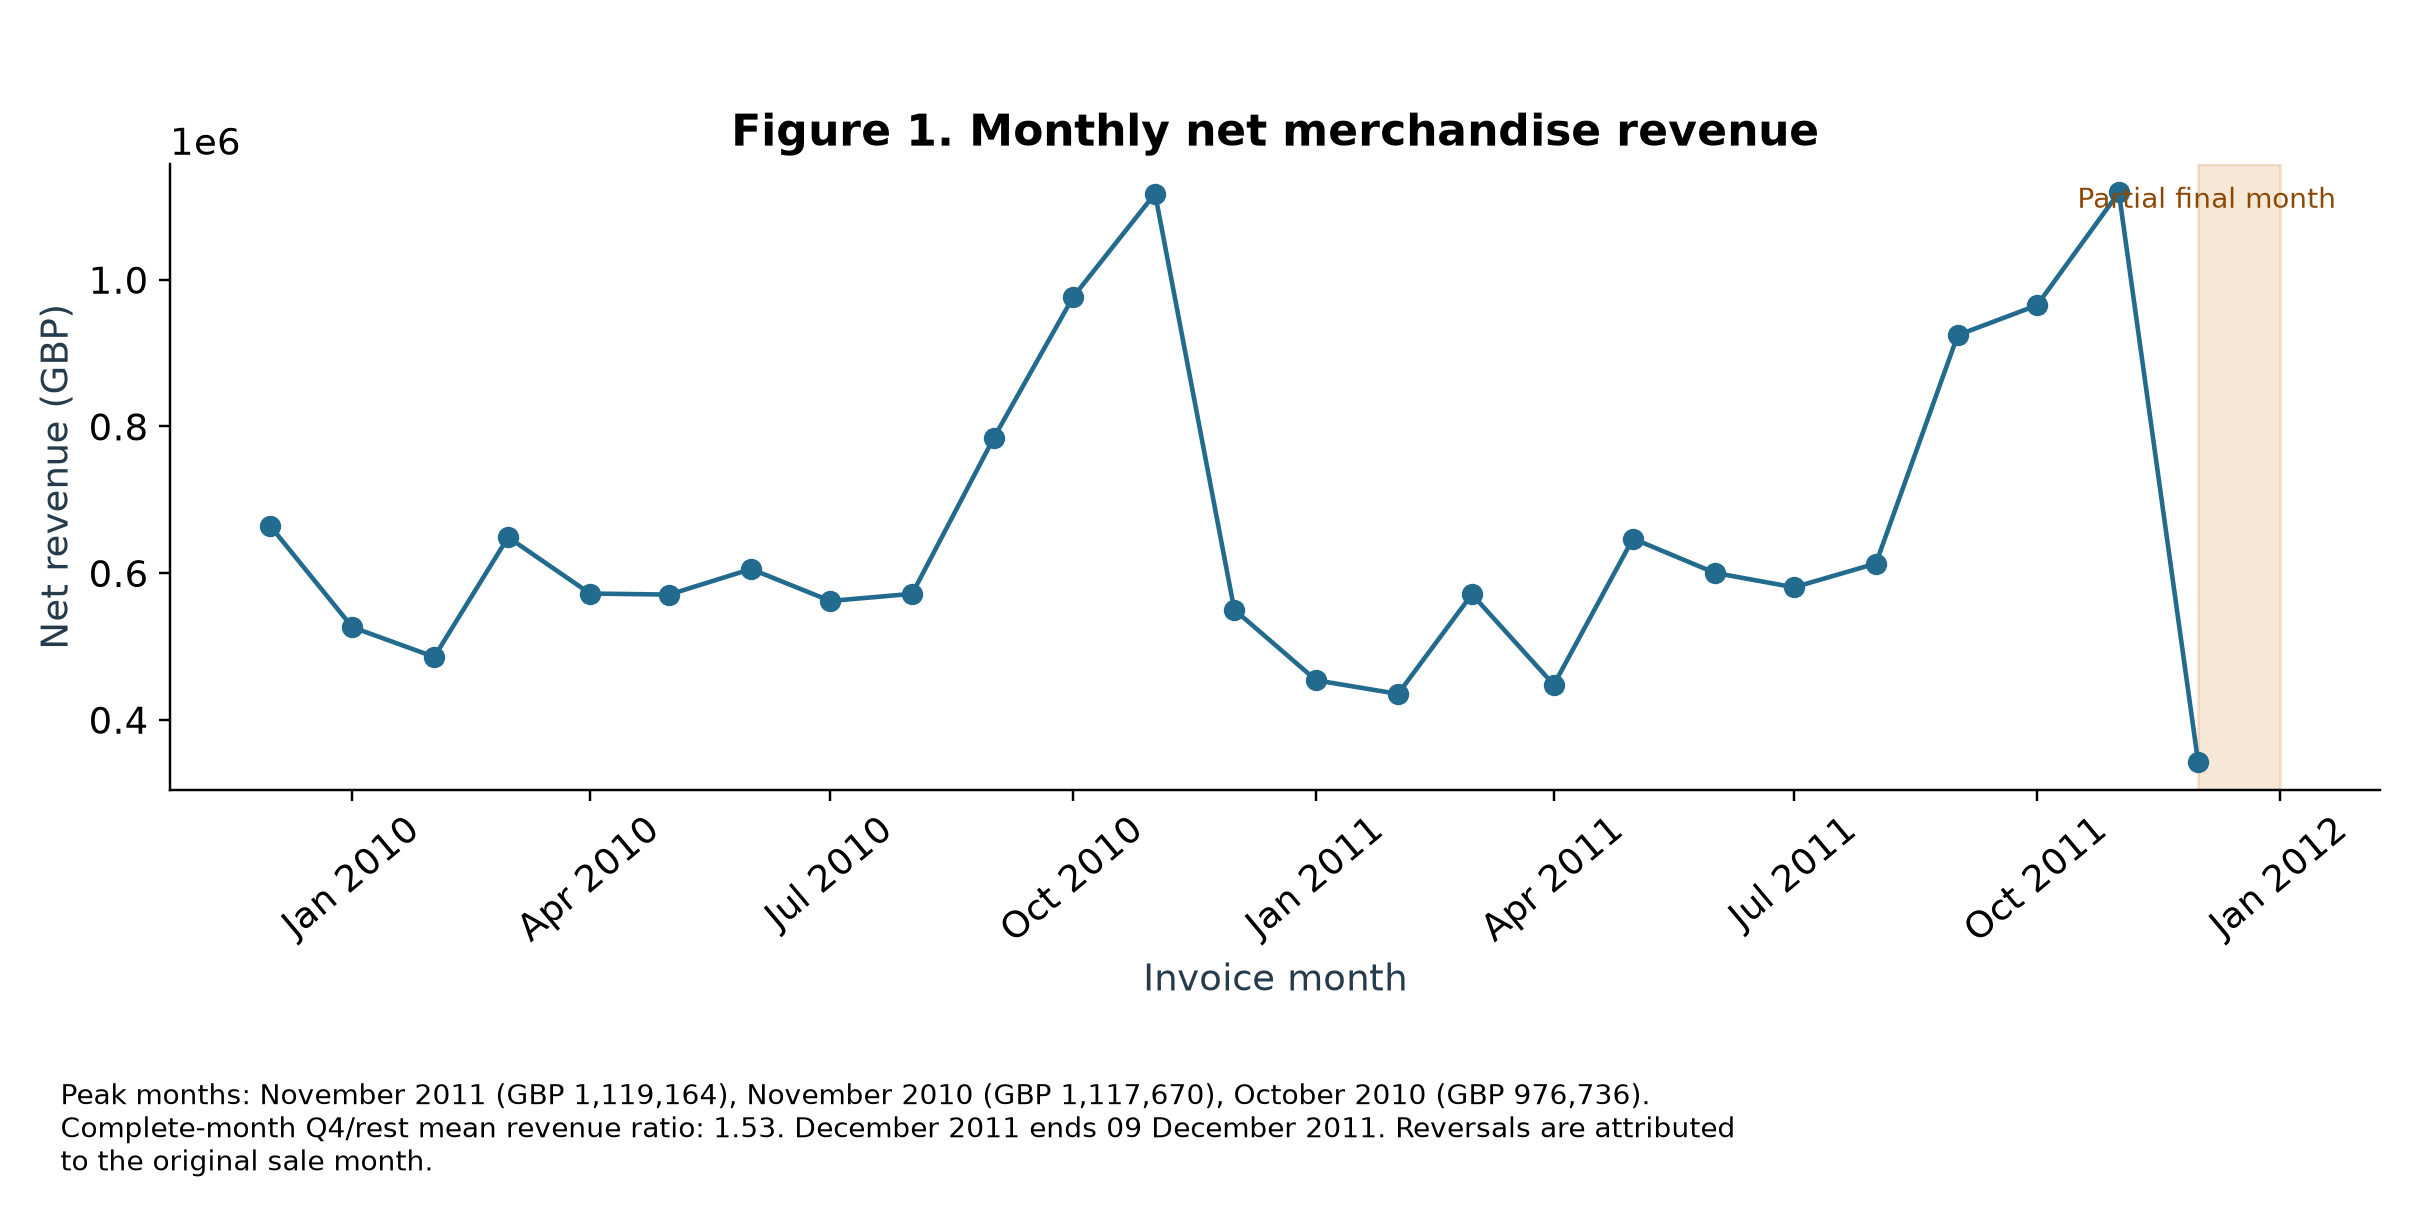

Peak months: November 2011 (GBP 1,119,164), November 2010 (GBP 1,117,670), October 2010 (GBP 976,736). Complete-month Q4/rest mean revenue ratio: 1.53. December 2011 ends 09 December 2011. Reversals are attributed to the original sale month.

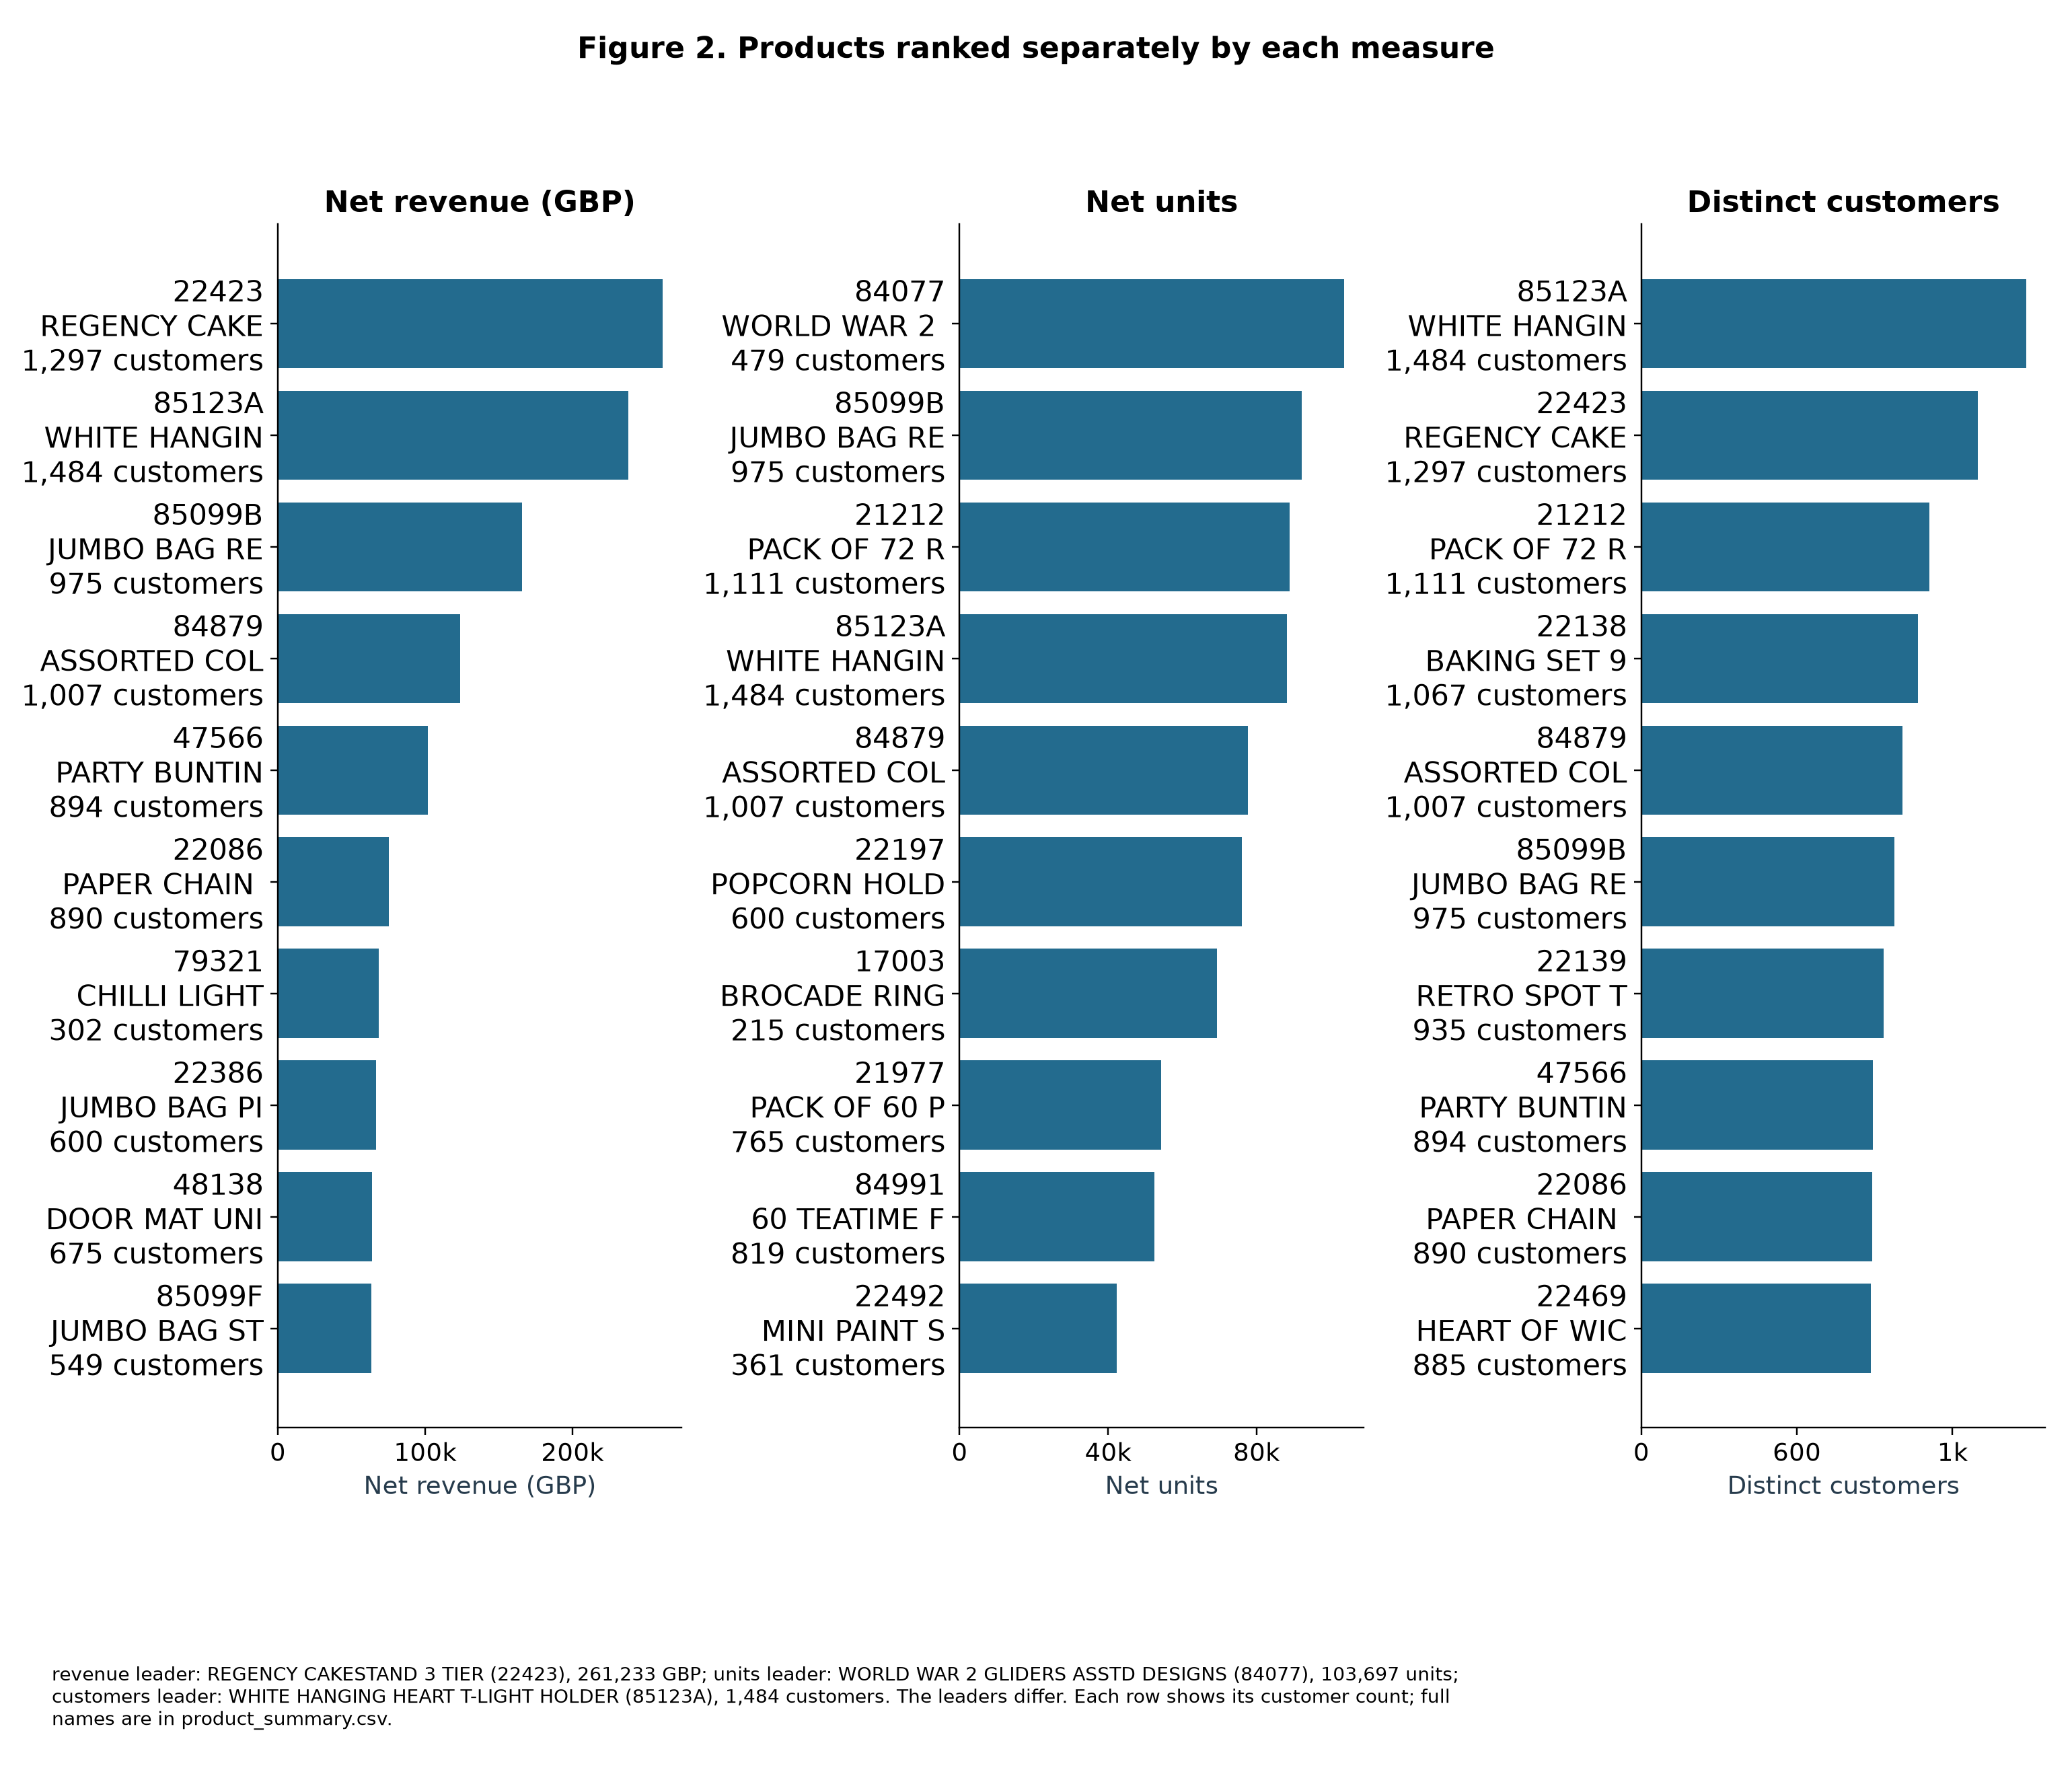

revenue leader: REGENCY CAKESTAND 3 TIER (22423), 261,233 GBP; units leader: WORLD WAR 2 GLIDERS ASSTD DESIGNS (84077), 103,697 units; customers leader: WHITE HANGING HEART T-LIGHT HOLDER (85123A), 1,484 customers. The leaders differ. Each row shows its customer count; full names are in product_summary.csv.

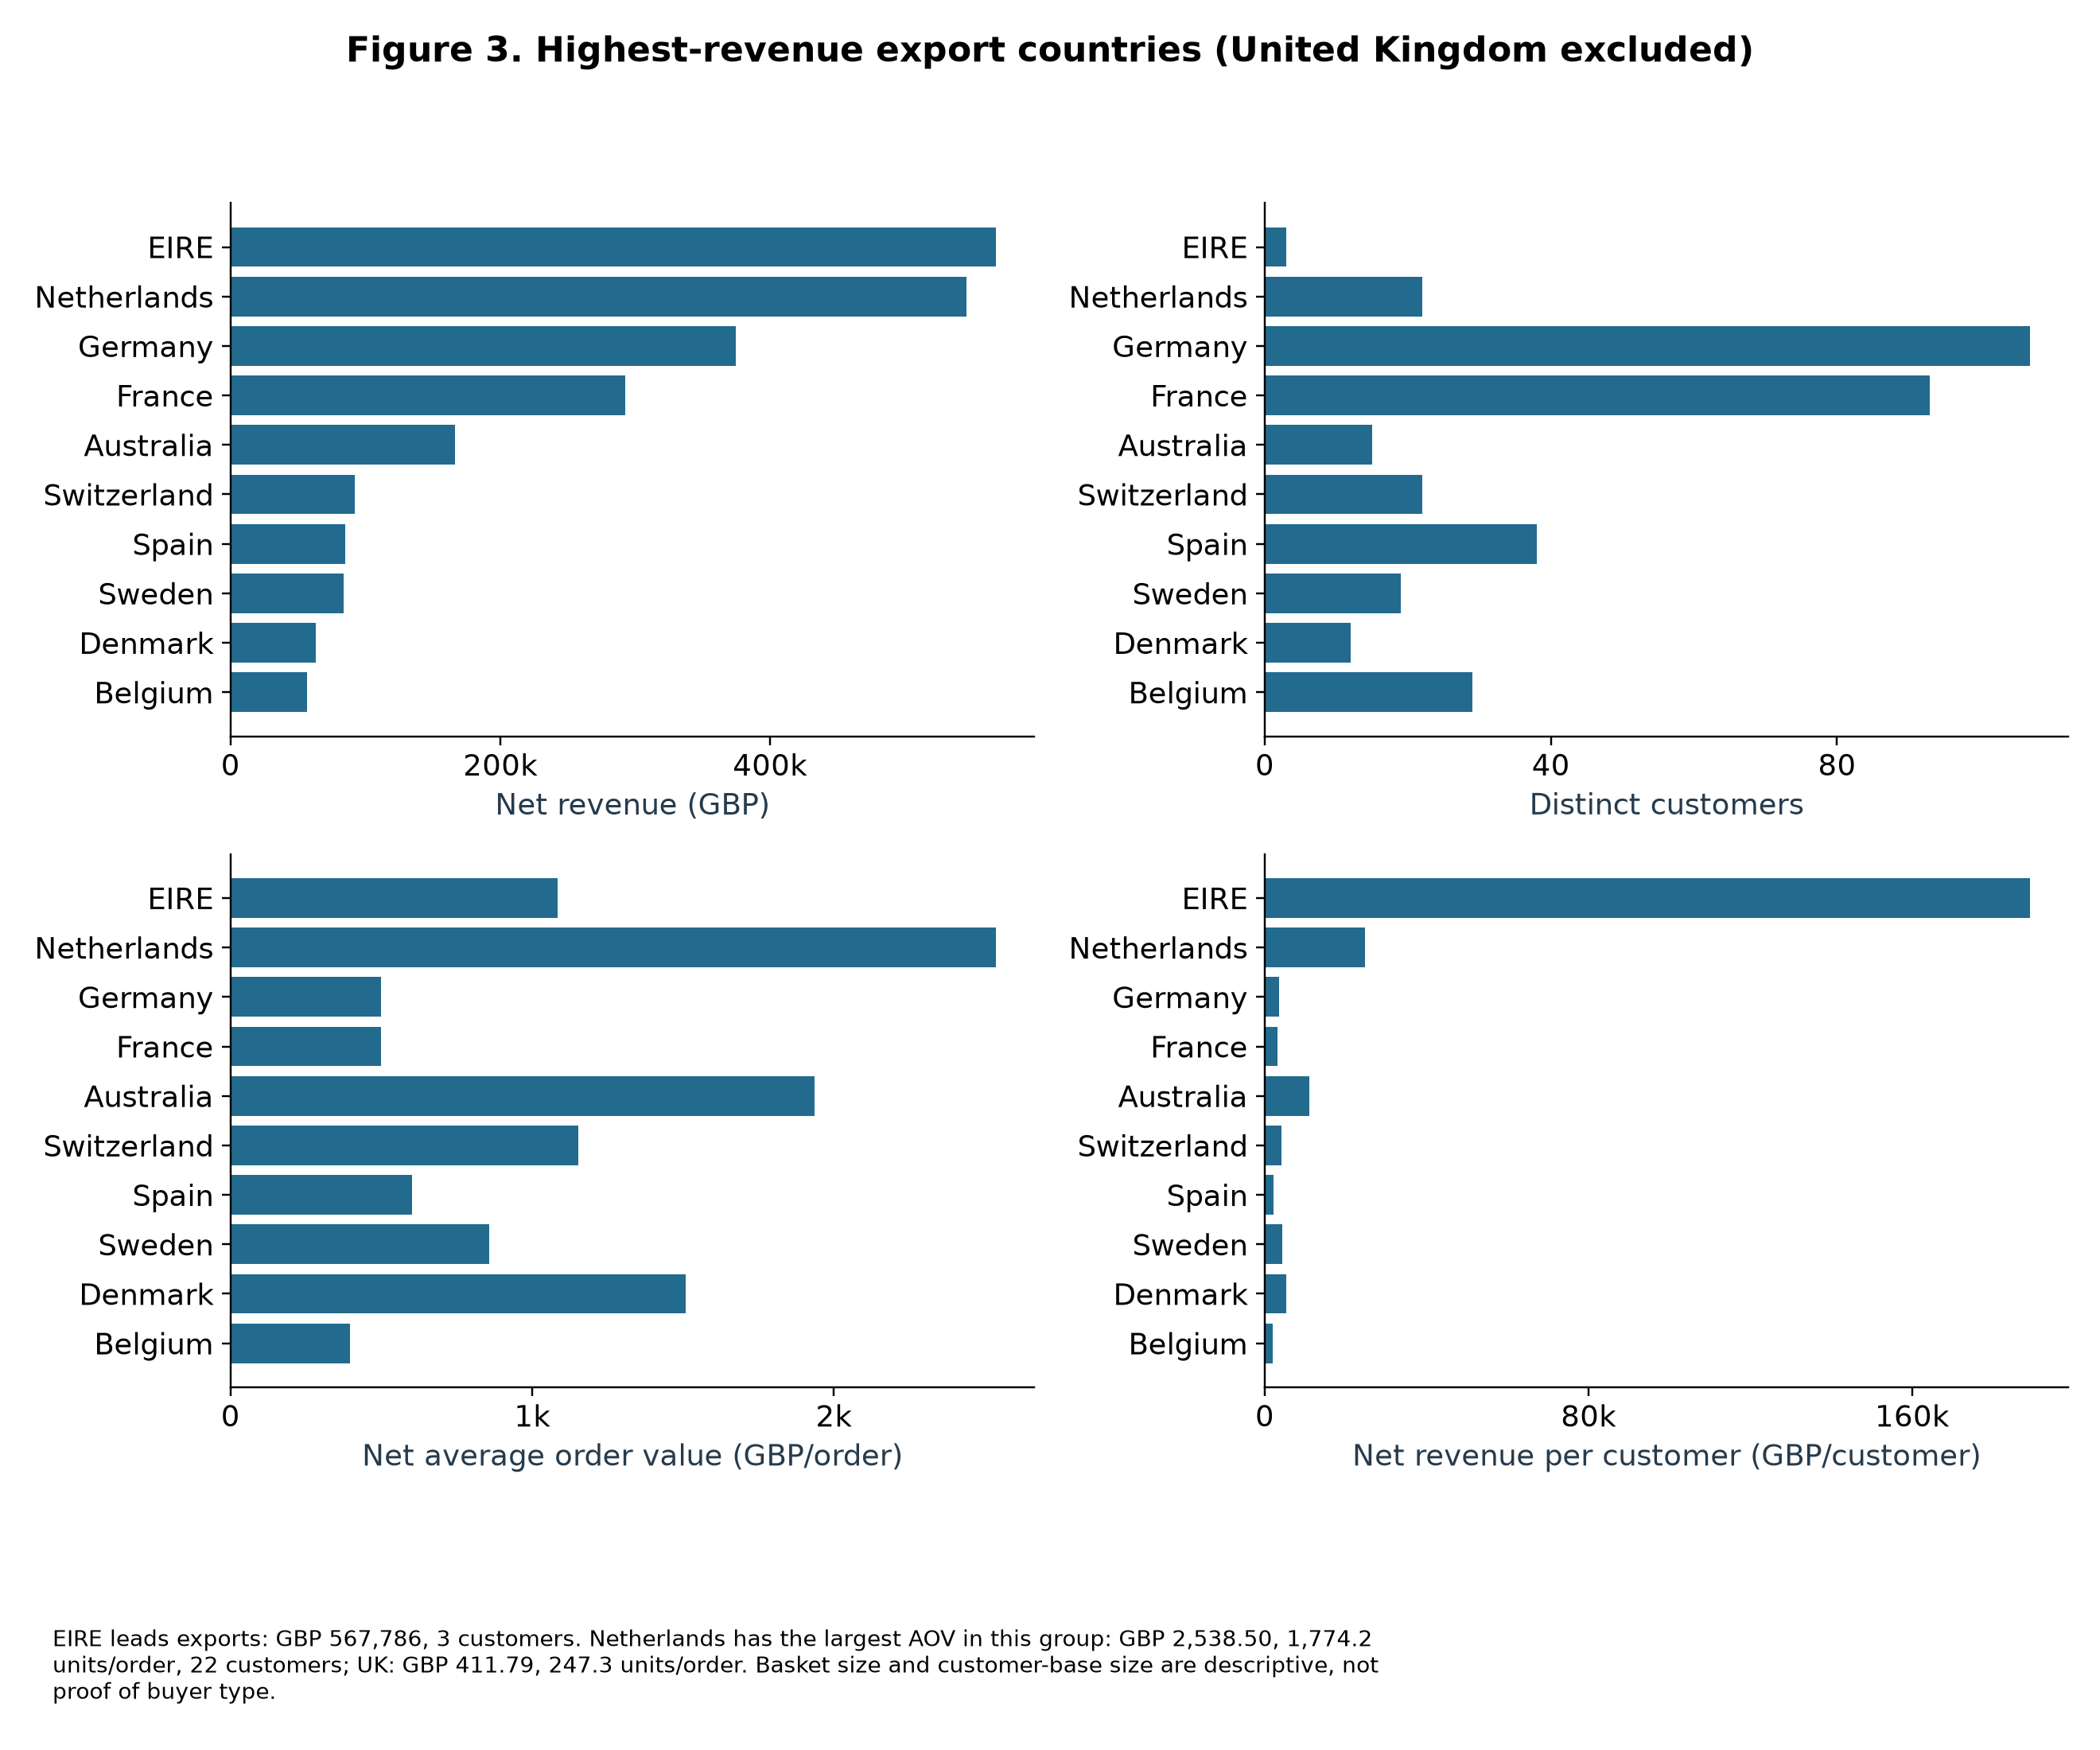

EIRE leads exports: GBP 567,786, 3 customers. Netherlands has the largest AOV in this group: GBP 2,538.50, 1,774.2 units/order, 22 customers; UK: GBP 411.79, 247.3 units/order. Basket size and customer-base size are descriptive, not proof of buyer type.

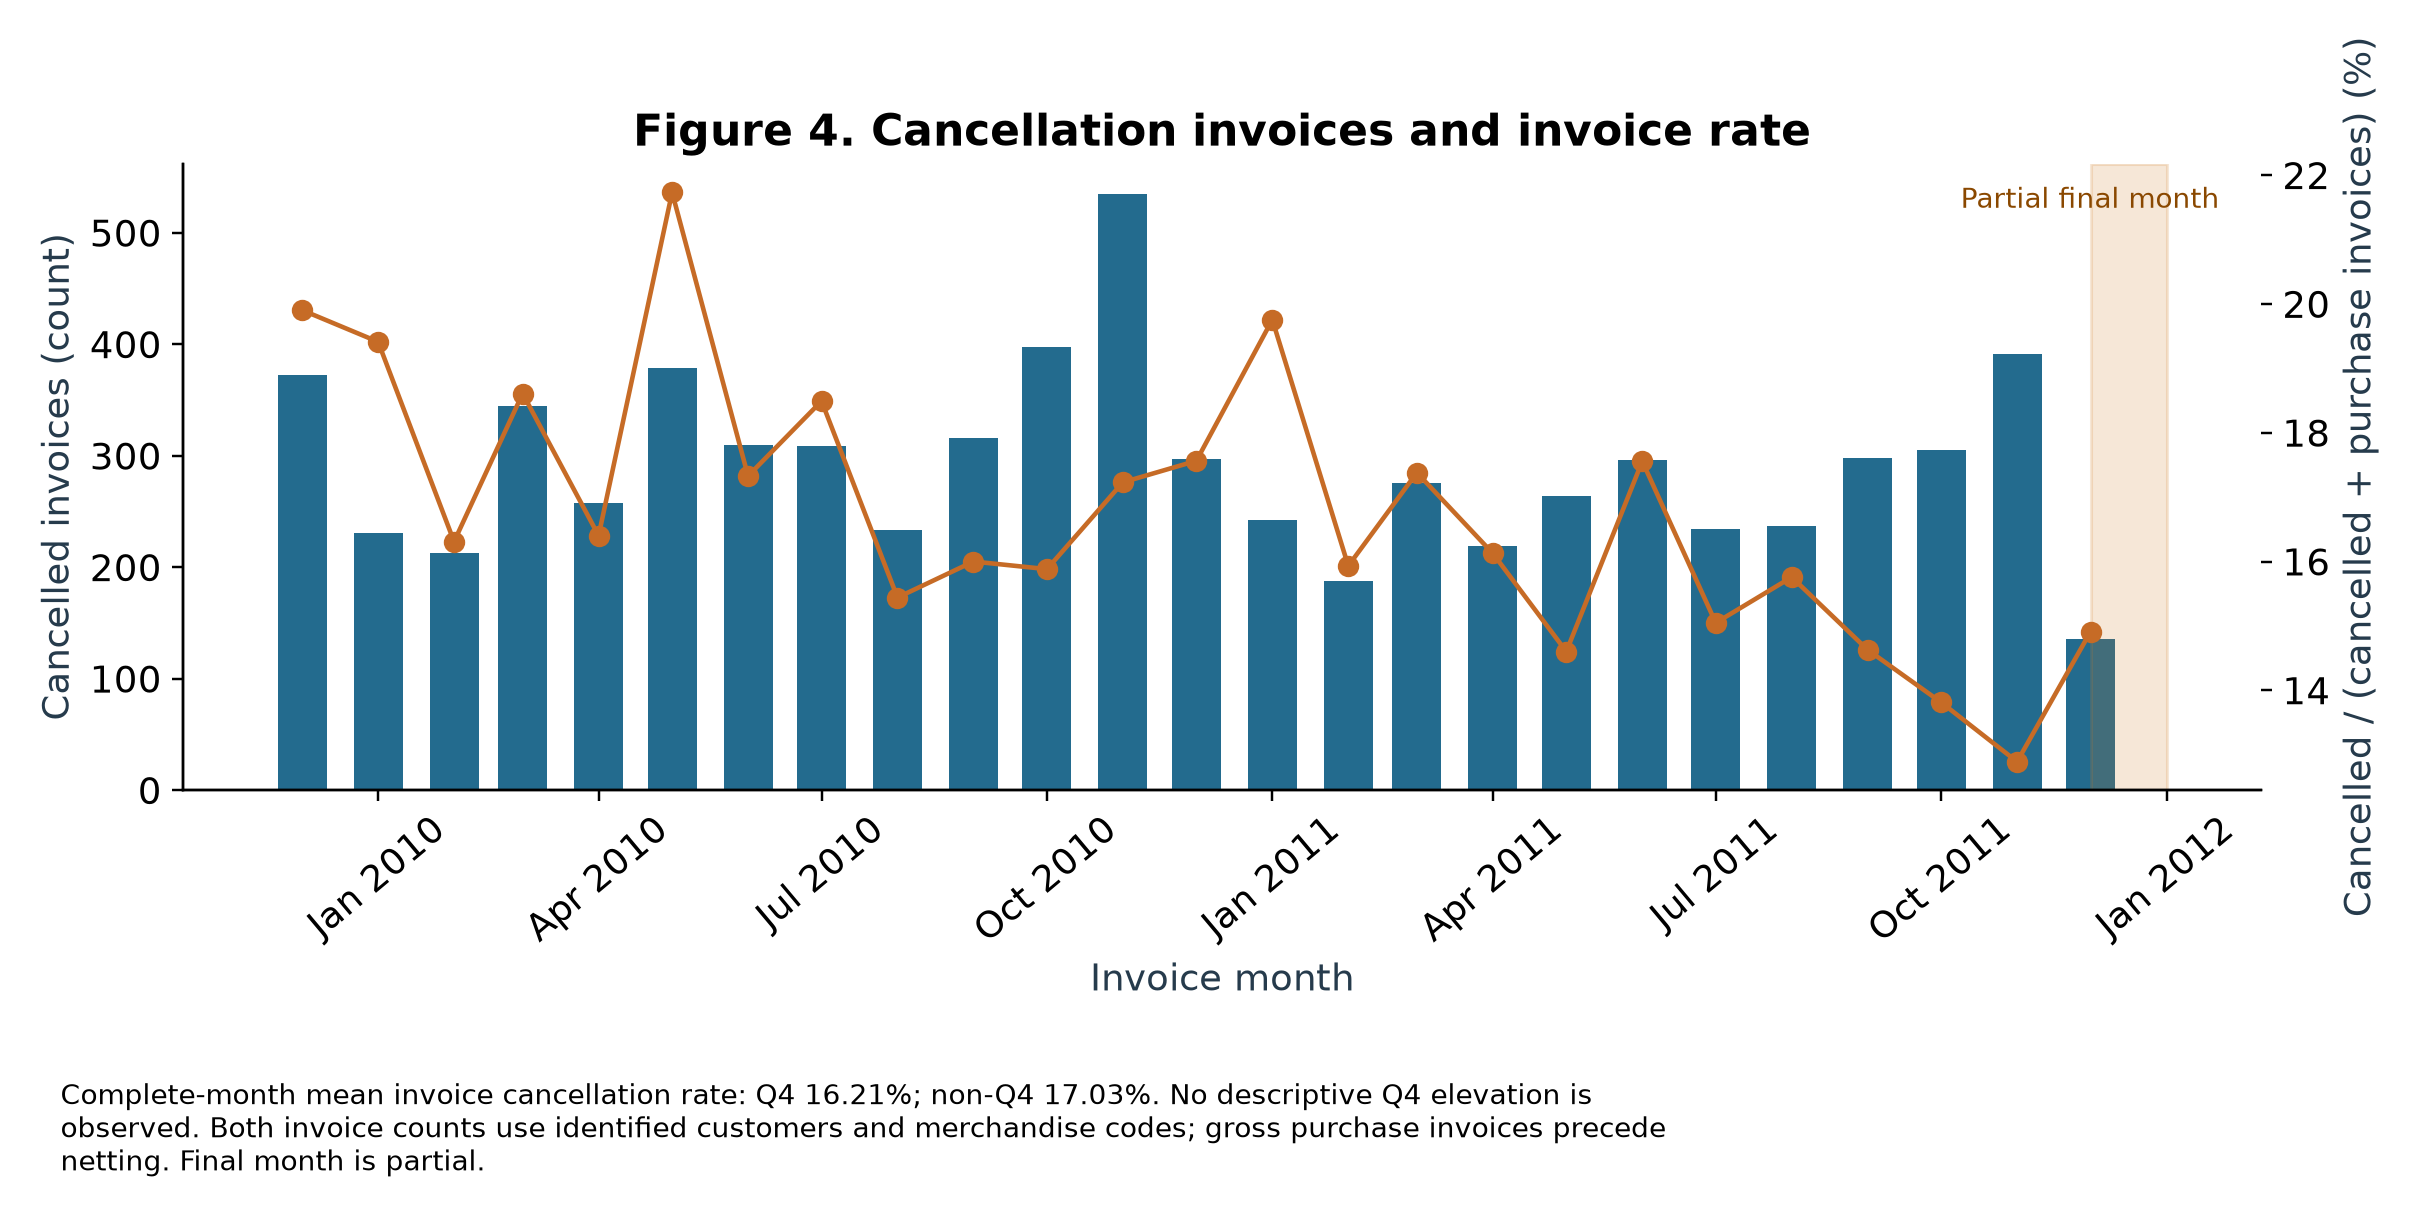

Complete-month mean invoice cancellation rate: Q4 16.21%; non-Q4 17.03%. No descriptive Q4 elevation is observed. Both invoice counts use identified customers and merchandise codes; gross purchase invoices precede netting. Final month is partial.

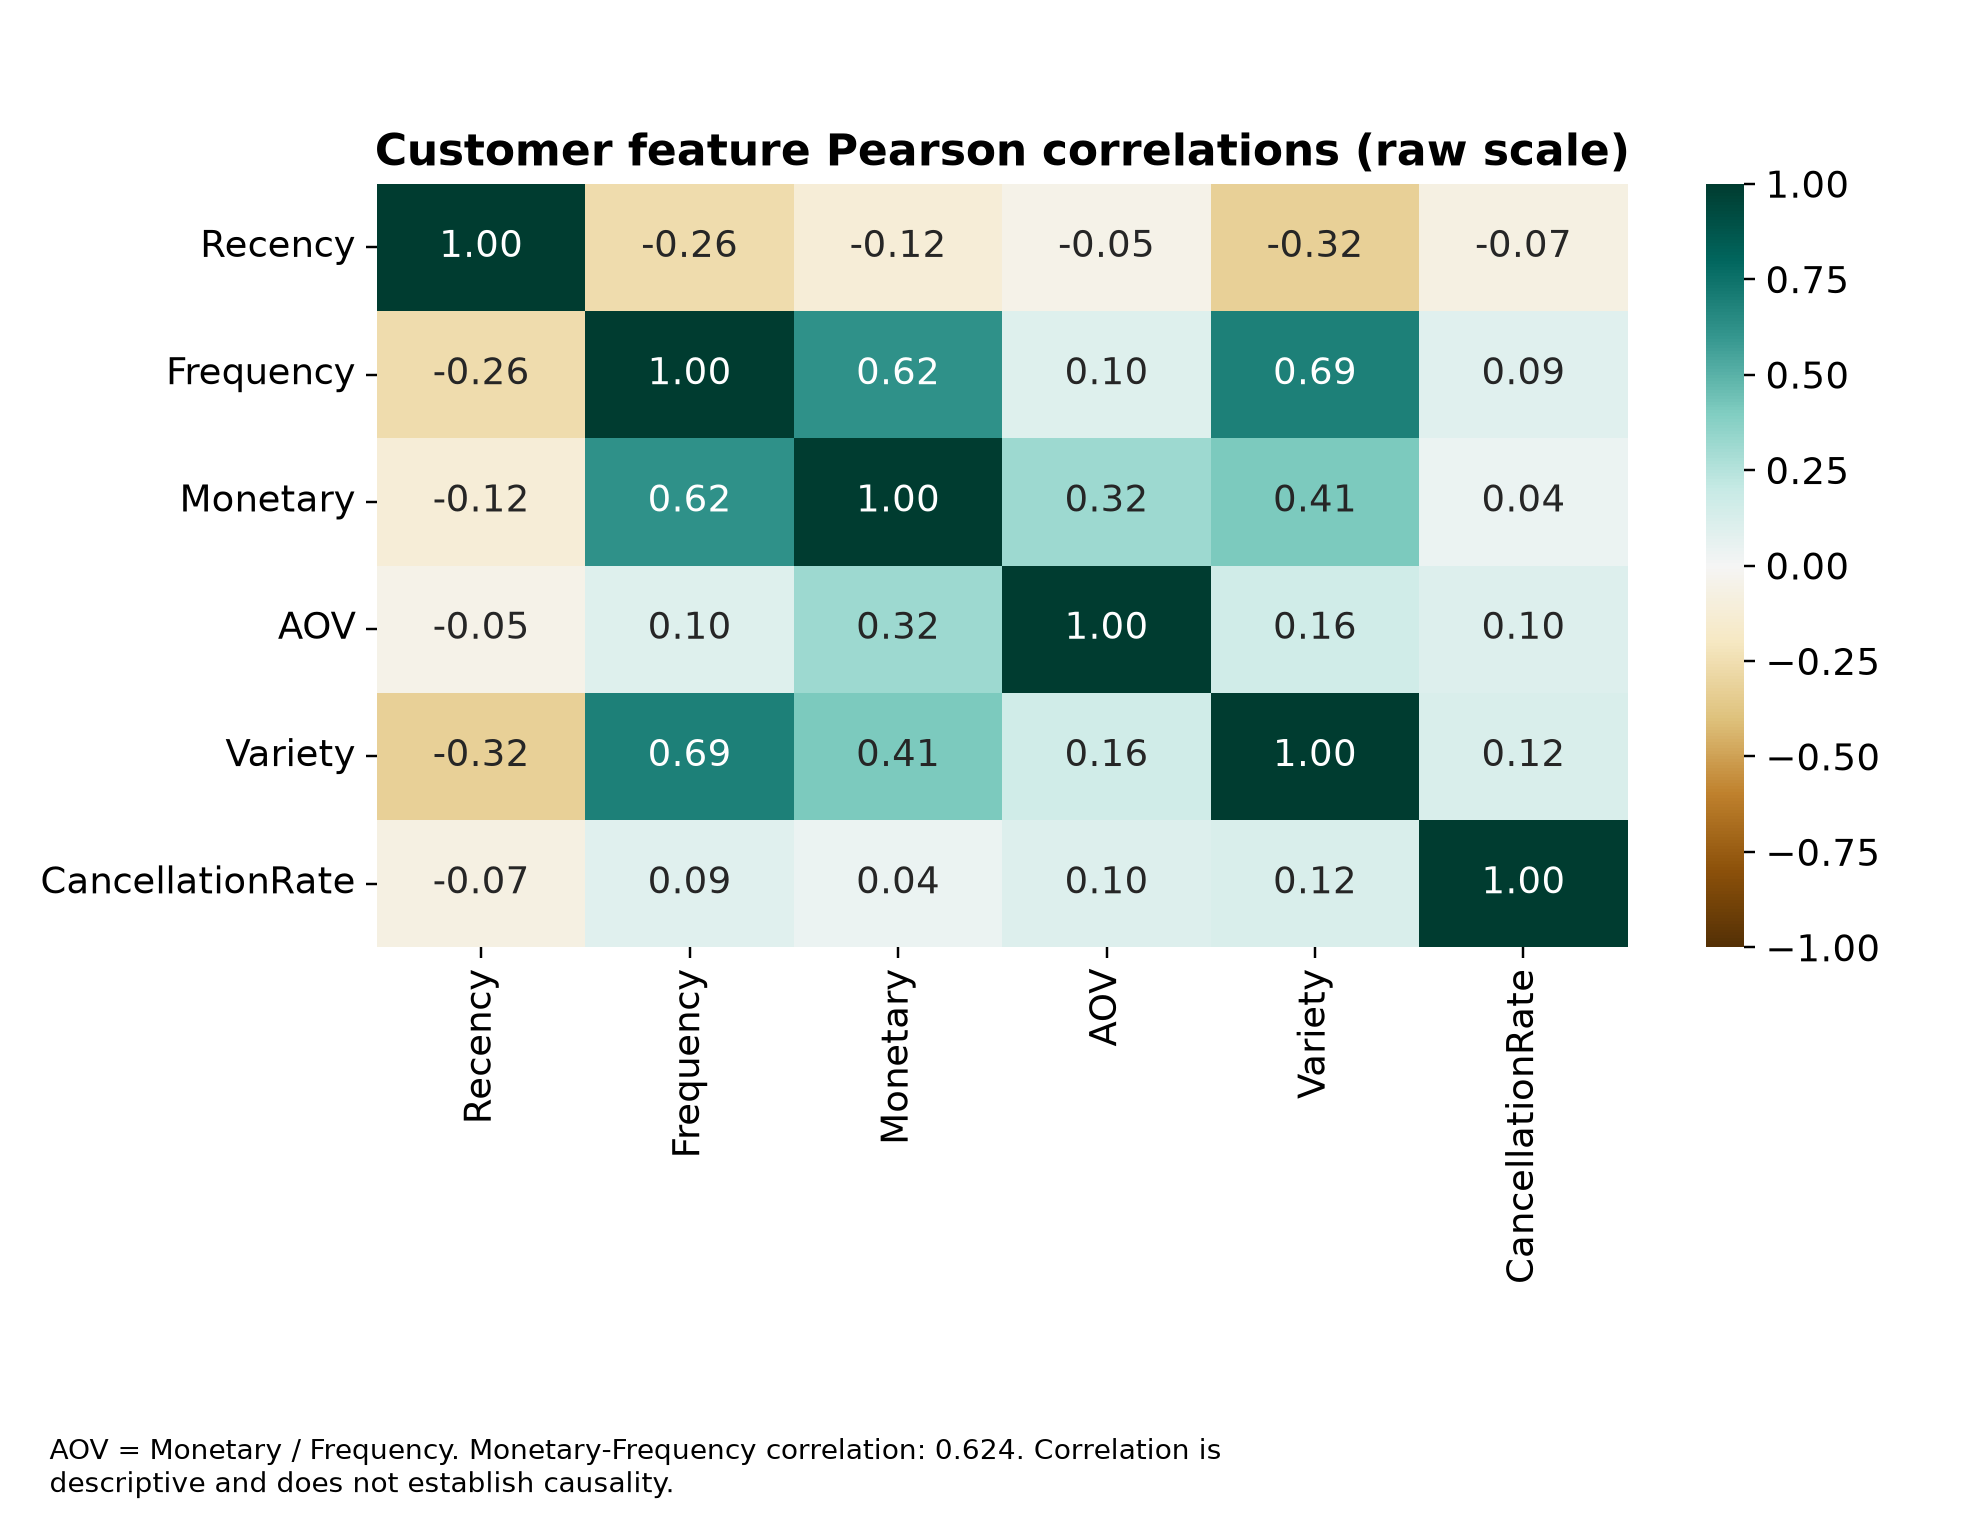

AOV = Monetary / Frequency. Monetary-Frequency correlation: 0.624. Correlation is descriptive and does not establish causality.

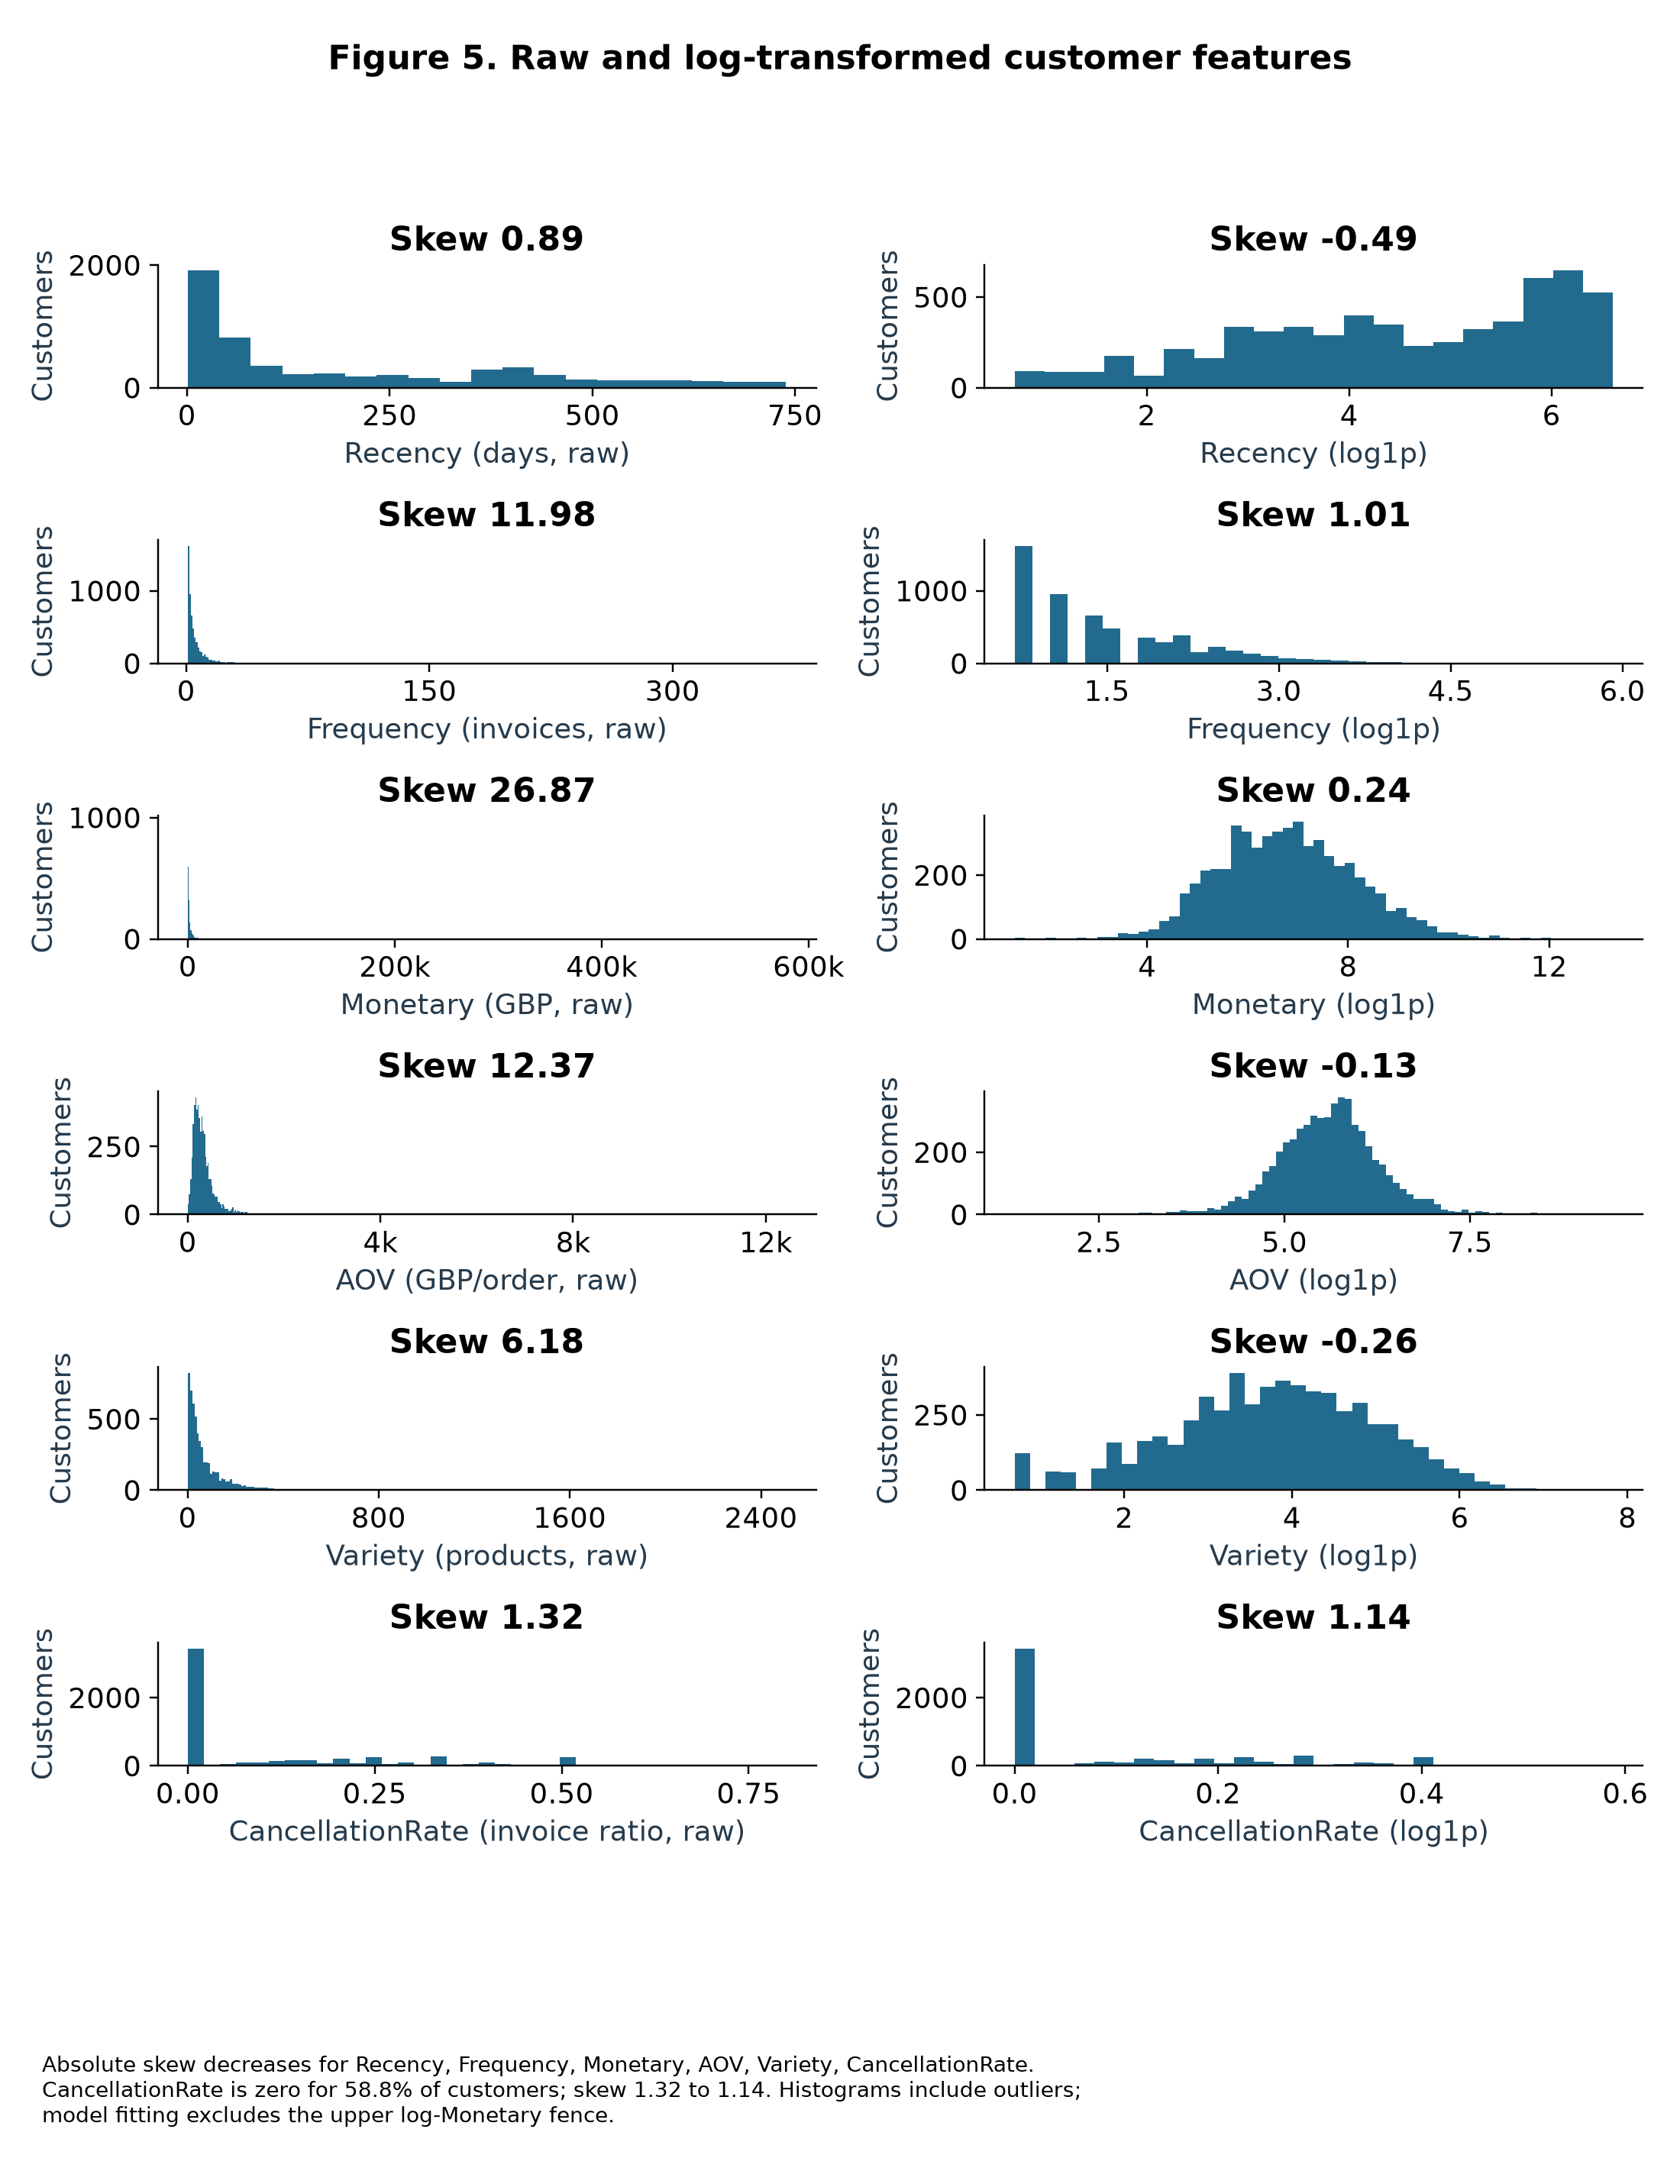

Absolute skew decreases for Recency, Frequency, Monetary, AOV, Variety, CancellationRate. CancellationRate is zero for 58.8% of customers; skew 1.32 to 1.14. Histograms include outliers; model fitting excludes the upper log-Monetary fence.

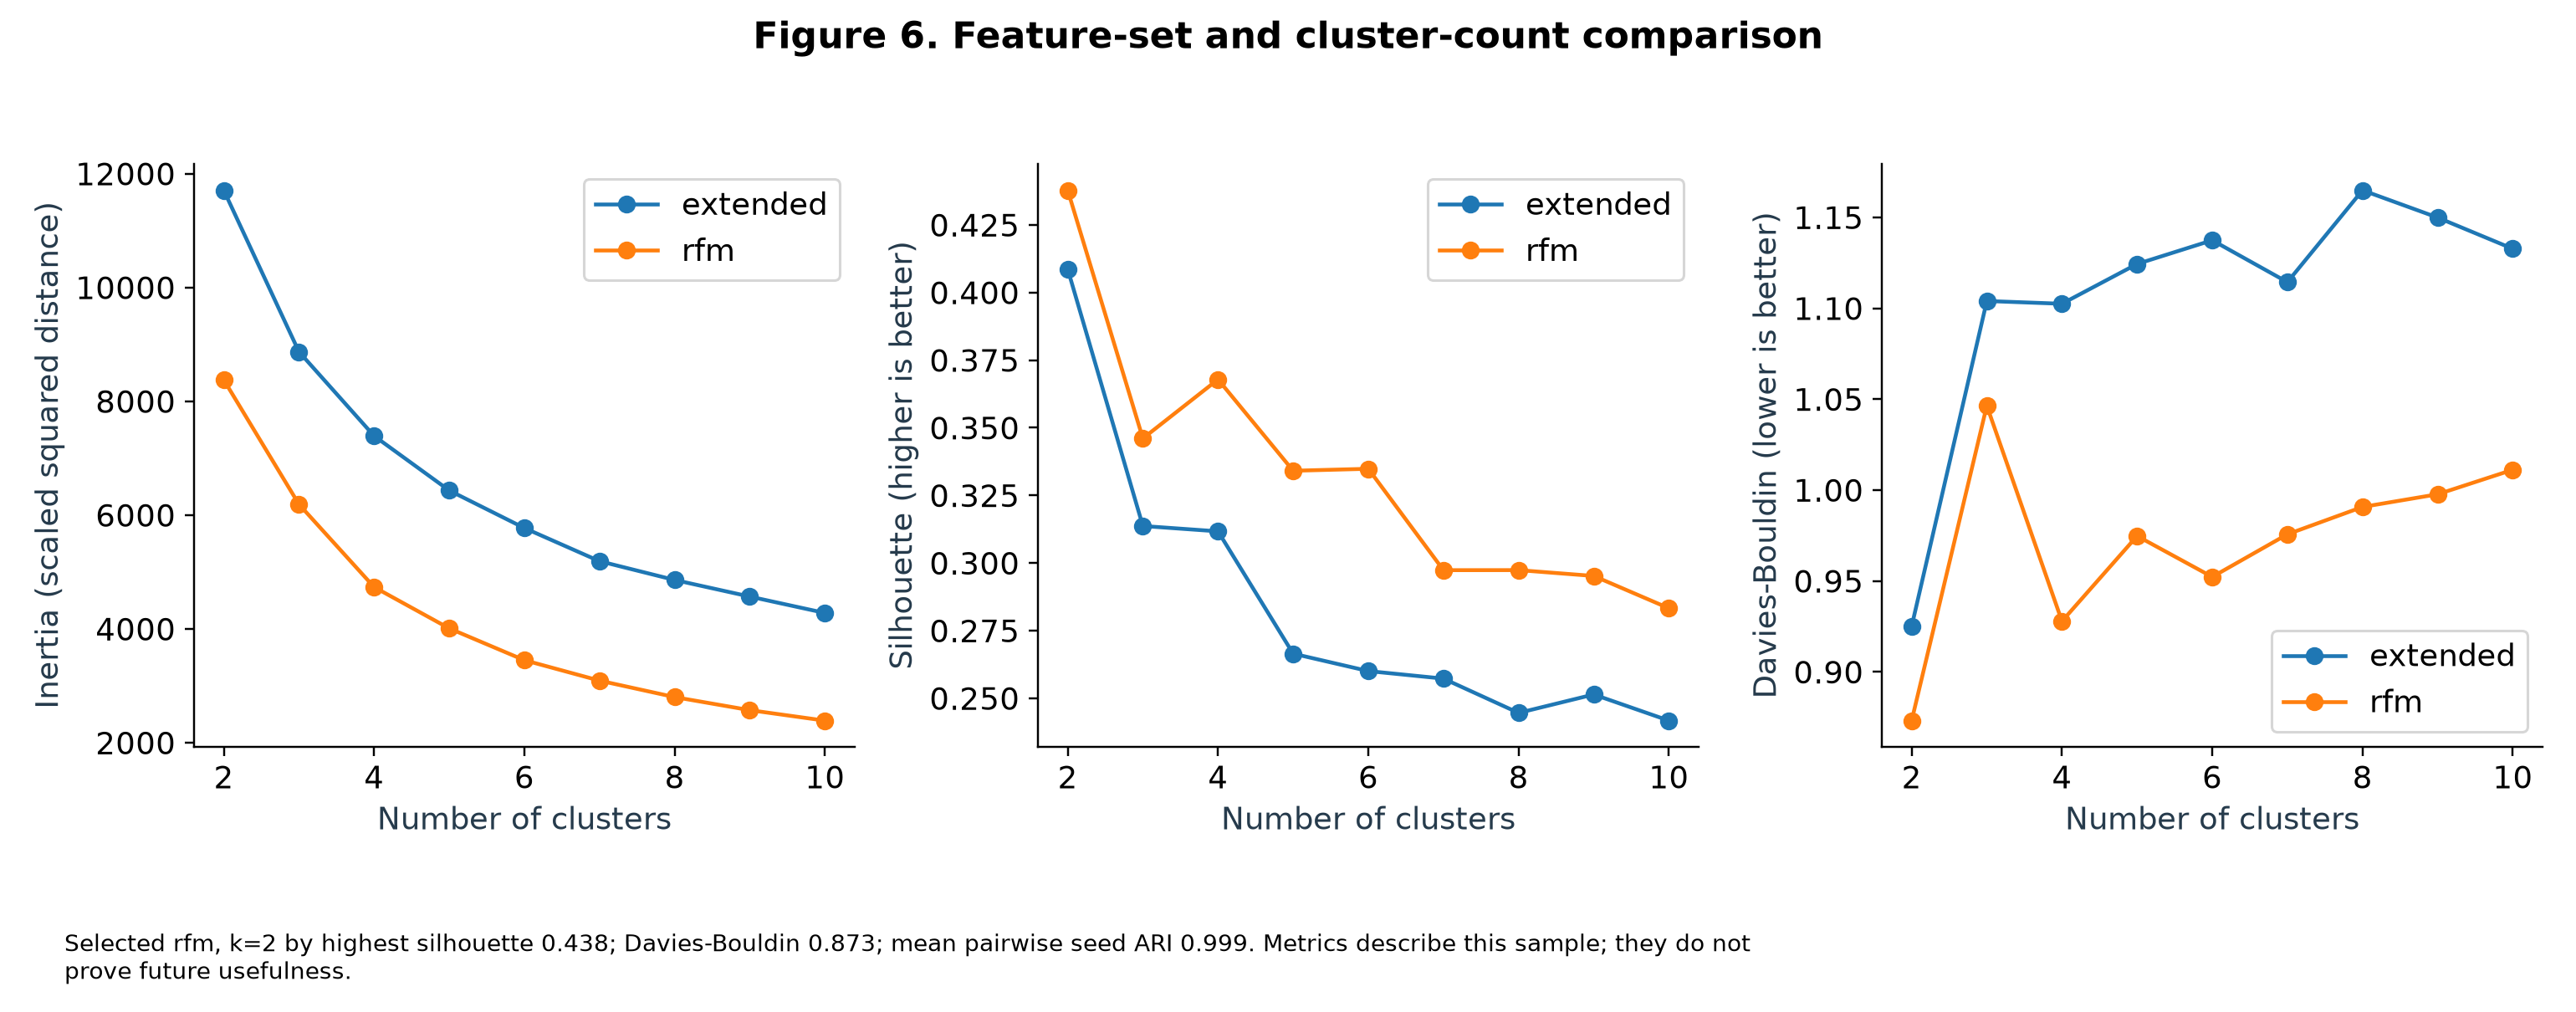

Selected rfm, k=2 by highest silhouette 0.438; Davies-Bouldin 0.873; mean pairwise seed ARI 0.999. Metrics describe this sample; they do not prove future usefulness.

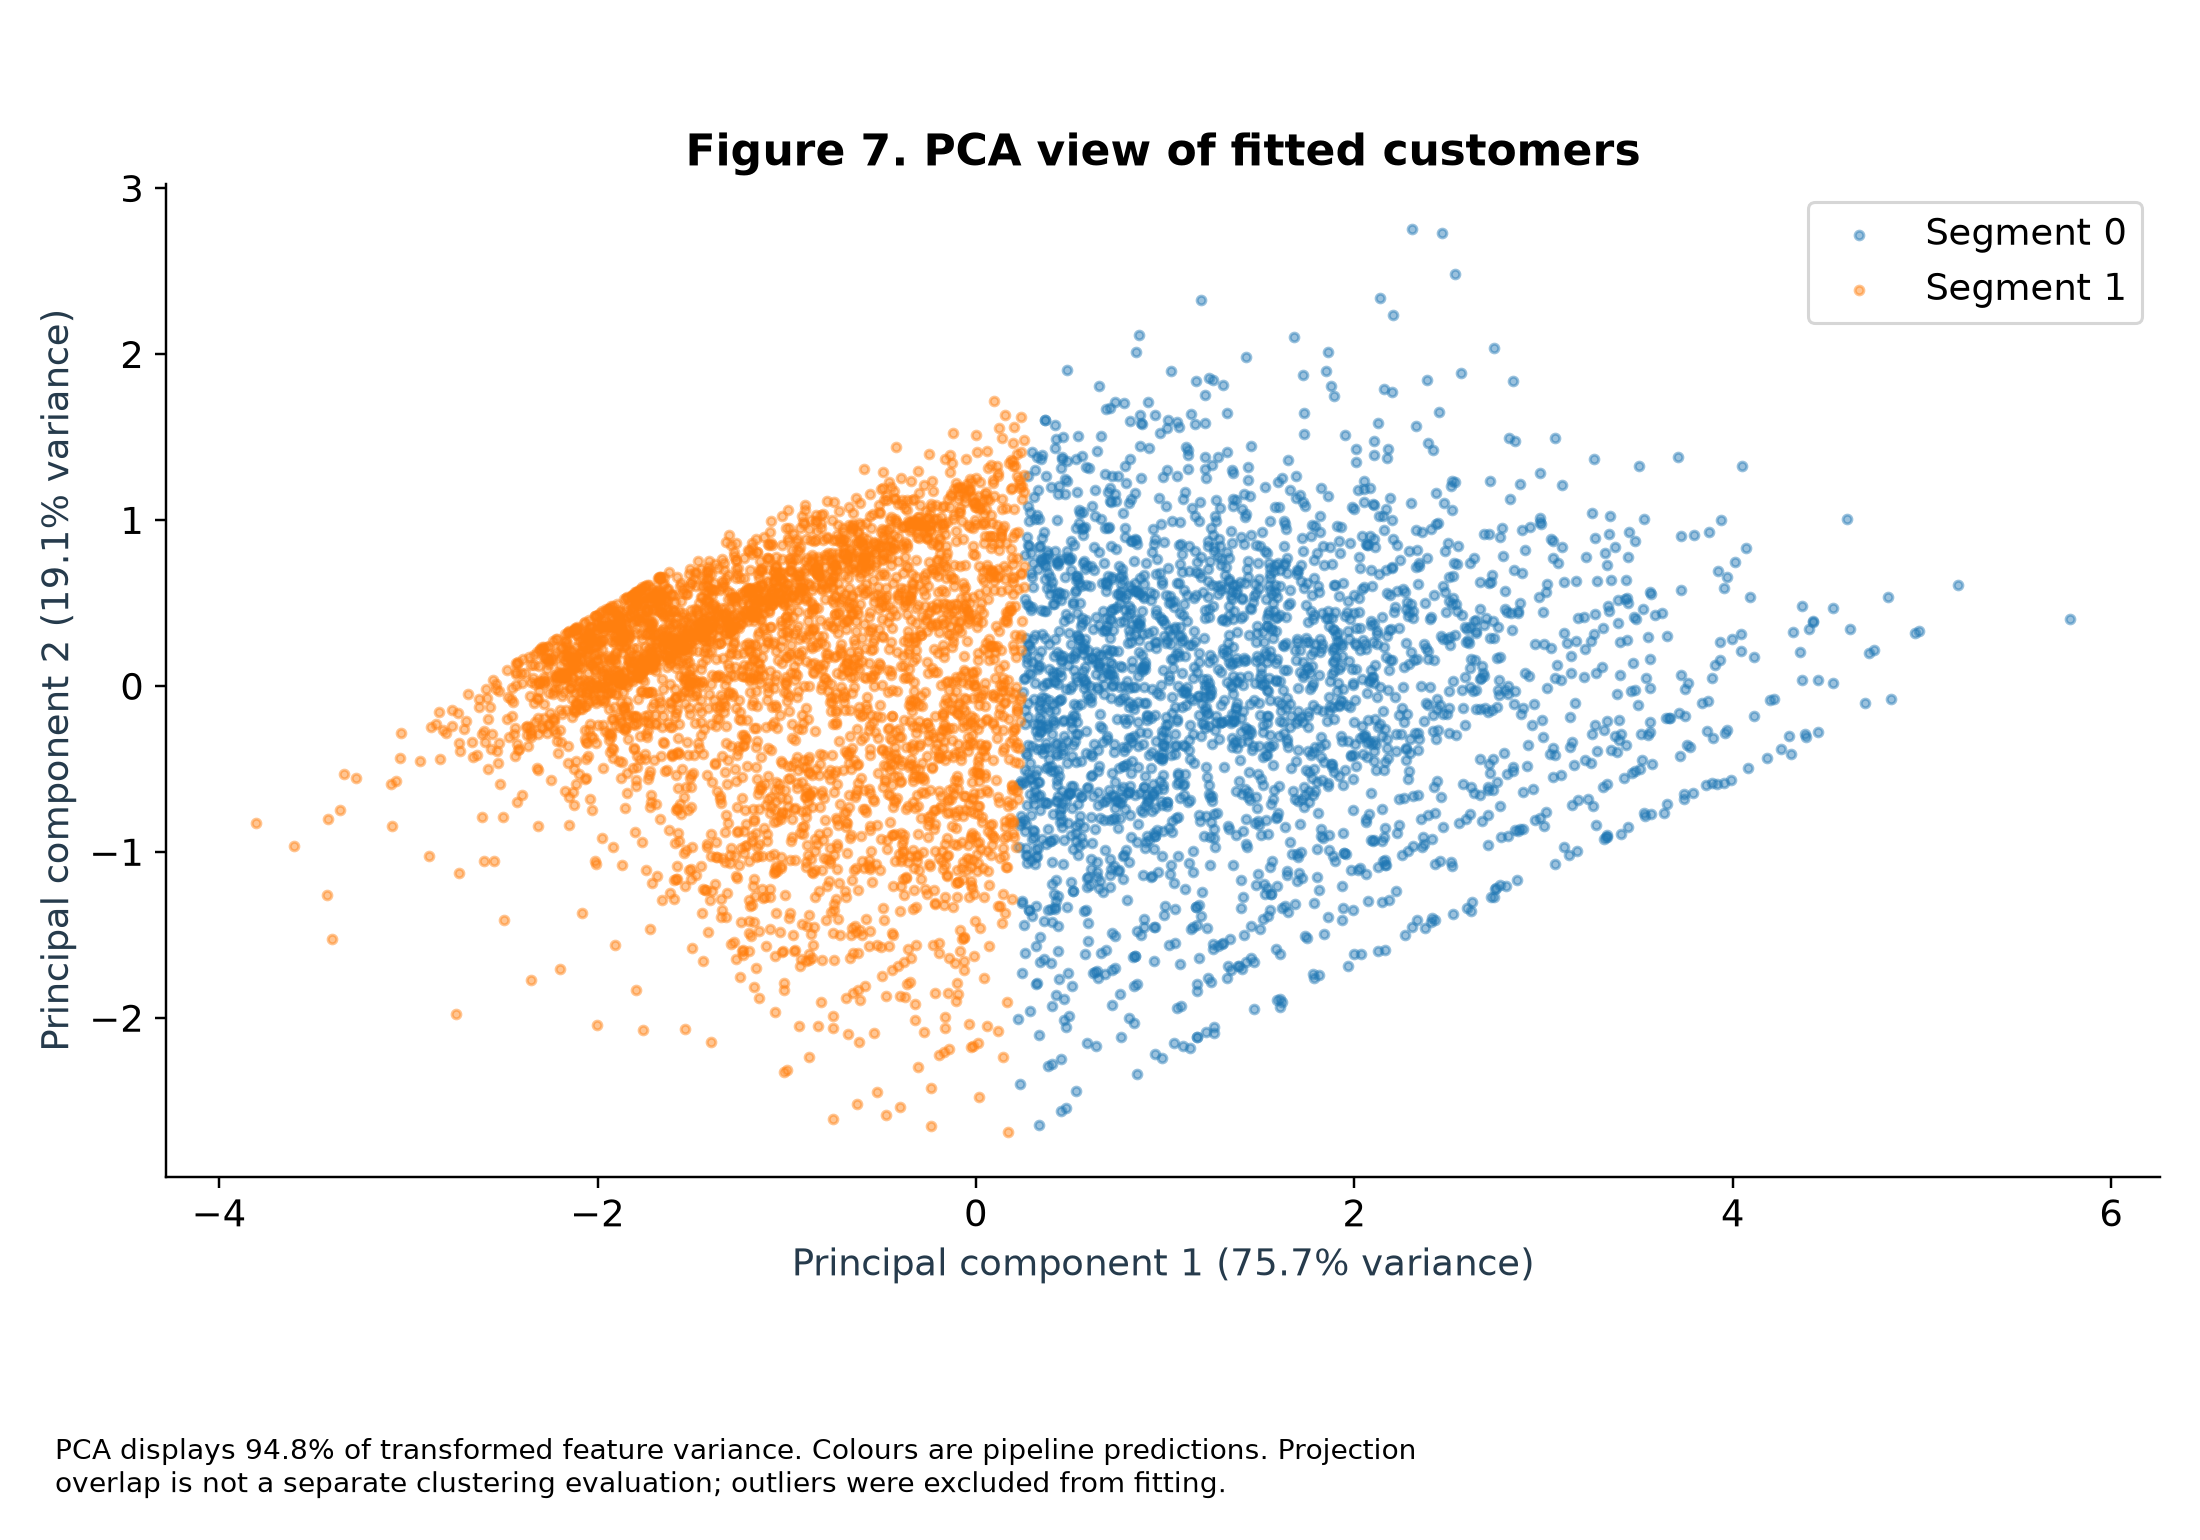

PCA displays 94.8% of transformed feature variance. Colours are pipeline predictions. Projection overlap is not a separate clustering evaluation; outliers were excluded from fitting.

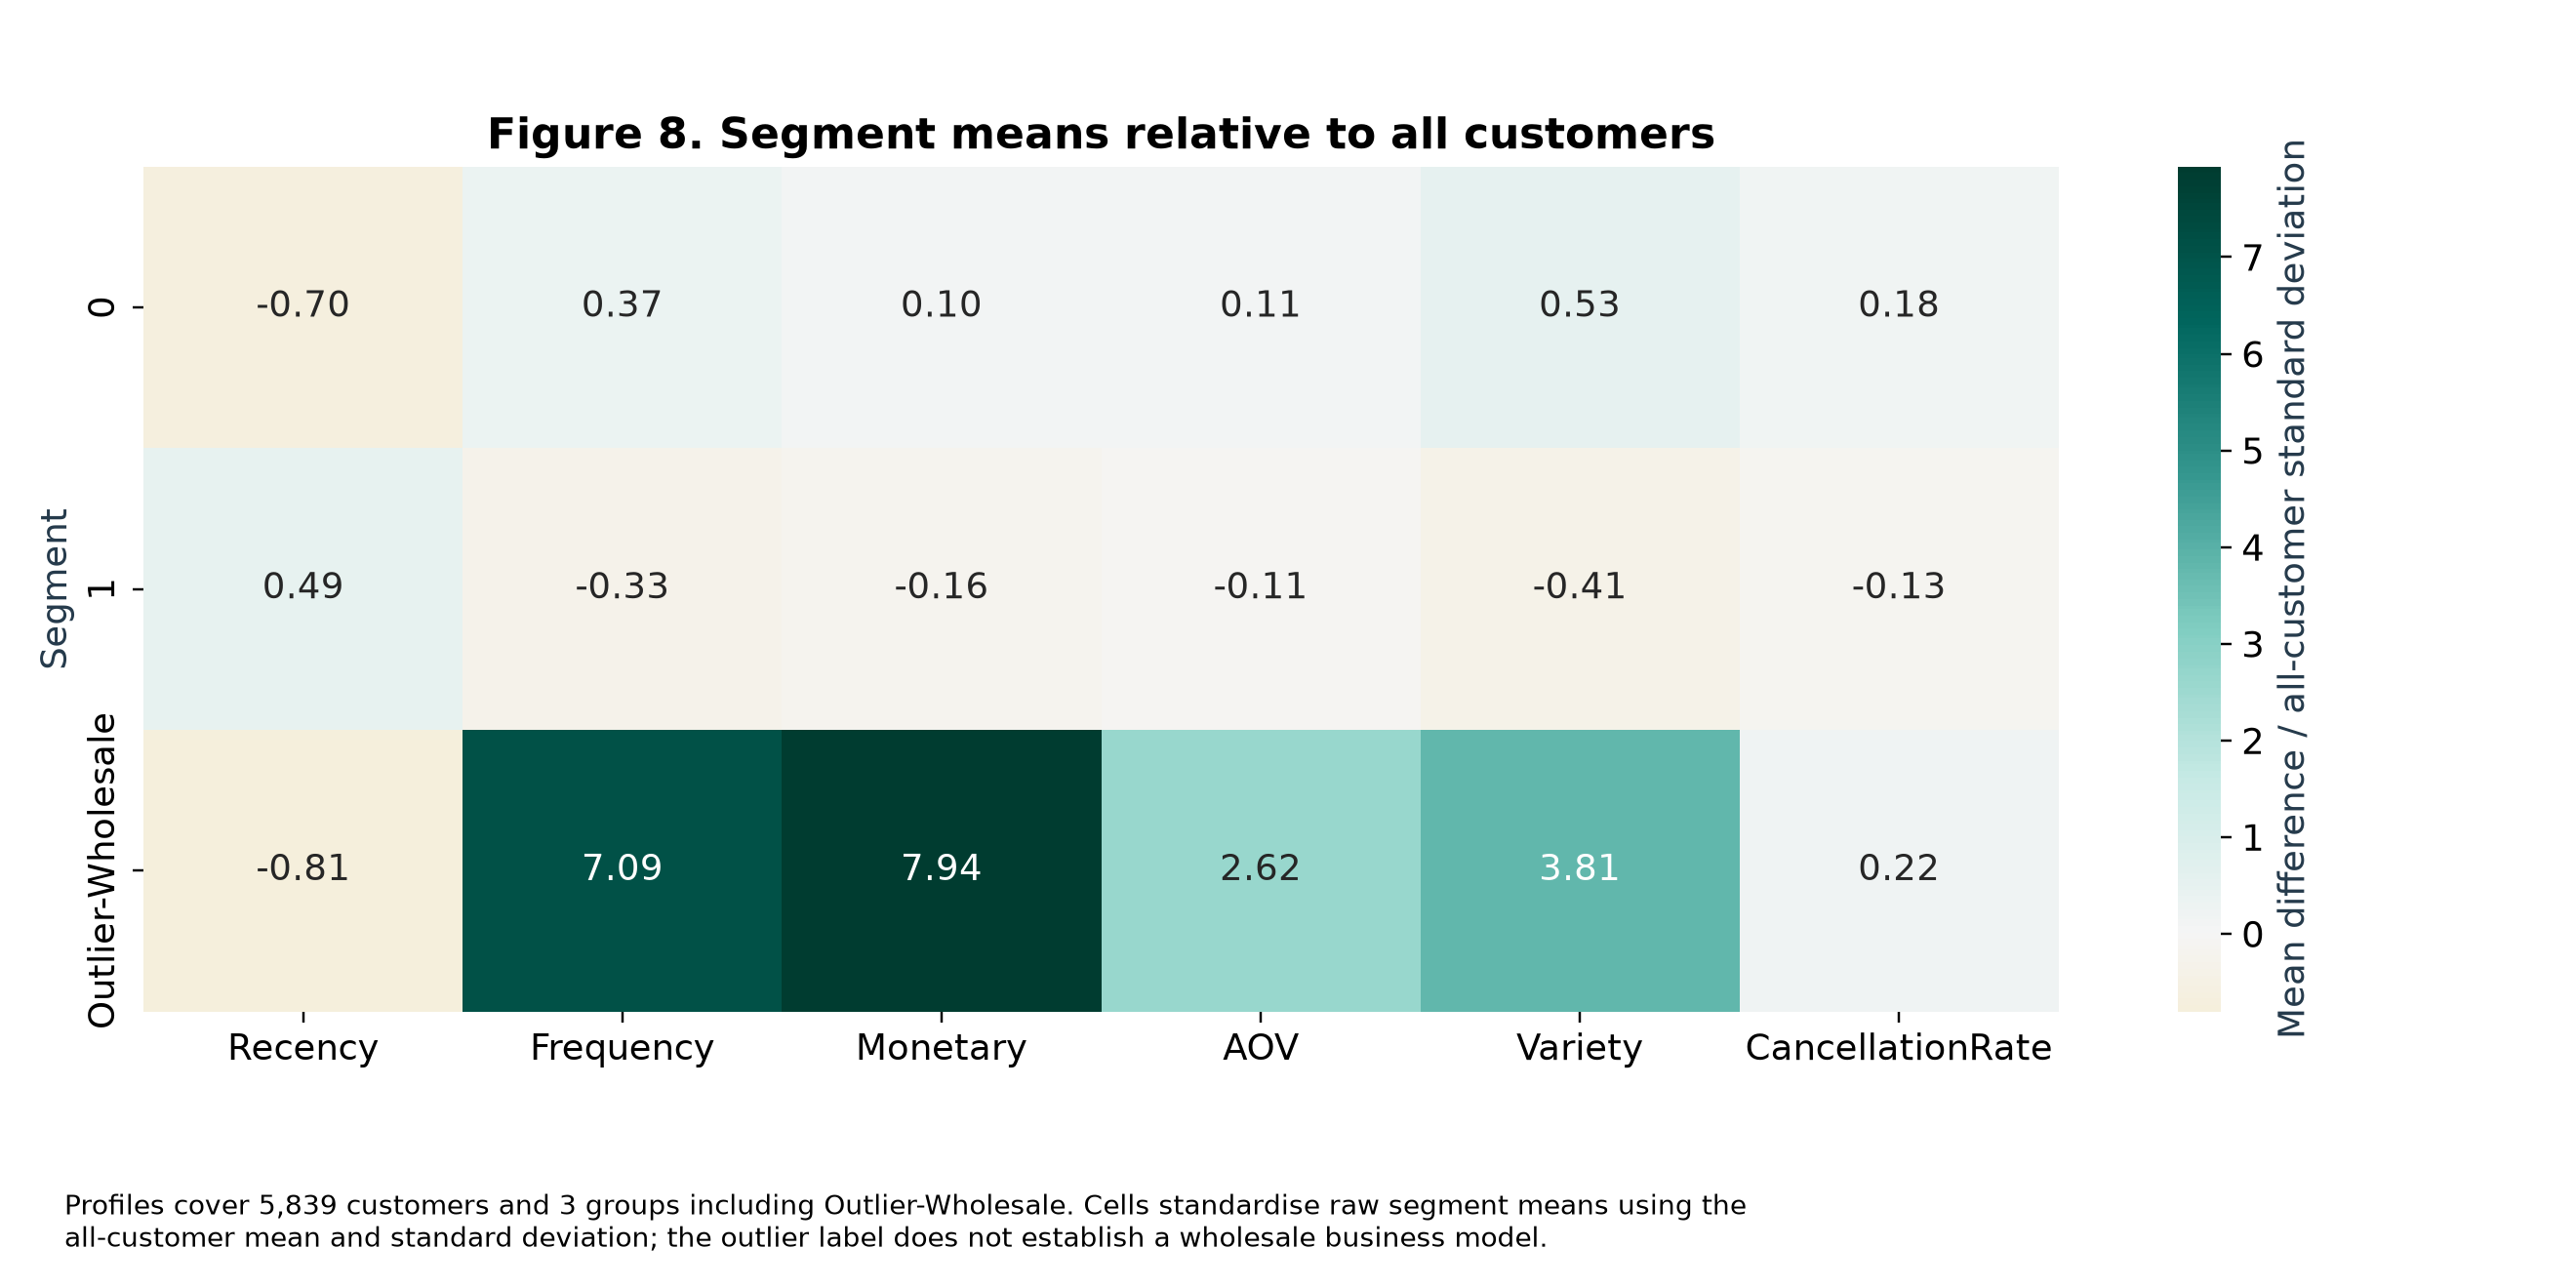

Profiles cover 5,839 customers and 3 groups including Outlier-Wholesale. Cells standardise raw segment means using the all-customer mean and standard deviation; the outlier label does not establish a wholesale business model.

In [7]:
from IPython.display import display, Image, Markdown
R = json.loads((root/'outputs/results.json').read_text(encoding='utf-8'))
for key, info in R['figures'].items():
    display(Image(filename=str(root/f'outputs/figures/{key}.png'), width=1000))
    display(Markdown(info['caption']))

## Reload and score raw customer inputs

In [8]:
# AOV is internally consistent, and the exact fitted feature order is preserved.
import joblib
import pandas as pd
model = joblib.load(root/'outputs/model/customer_segmentation.joblib')
features = R['model']['features']
print('Feature order:', ', '.join(features))
print('Selected k:', R['model']['k'])
example = pd.DataFrame([R['model_test']['inputs']])[features]
label = str(int(model.predict(example)[0]))
assert label == R['model_test']['label']
assert R['model_test']['inputs']['AOV'] == R['model_test']['inputs']['Monetary']/R['model_test']['inputs']['Frequency']
print(example.to_string(index=False))
print(R['segments'][label]['name'])
print(pd.DataFrame(R['segments']).T.to_string())
print('Recorded regression checks:', R['regression'])

Feature order: Recency, Frequency, Monetary
Selected k: 2
 Recency  Frequency  Monetary
    96.0        3.0     837.0
Dormant occasional buyers
                   size customer_share     revenue revenue_share recency_mean recency_median frequency_mean frequency_median monetary_mean monetary_median    aov_mean  aov_median variety_mean variety_median cancellationrate_mean cancellationrate_median                                                         tags                       name                                                                                                                    action
0                  2347       0.401952   9860691.3      0.603522    53.681295           25.0      10.855134              8.0   4201.402343         2610.28  411.622189  326.378462   143.838517          111.0              0.139866                   0.125  {'recency': 'low', 'frequency': 'high', 'monetary': 'high'}            Loyal champions                        Offer early access to relevan

## How AI was used

AI assisted with code, debugging, narrative drafting and validation. All numerical claims come from executed computations against the supplied files. Group members must review the reasoning, verify the citation, complete the ethics declaration and explain the notebook themselves. AI is an authoring tool, not a source of new retail facts.